<a href="https://colab.research.google.com/github/NicoCisternas1111/EP1_DLY0100_MLP_BankMarketing/blob/main/EP1_DLY0100_MLP_BankMarketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluación Parcial 1 — Red Neuronal Multicapa (MLP) para predecir la contratación de un depósito a plazo

**Asignatura:** DLY0100 · Deep Learning  
**Integrantes:** Nicolás Cisternas · Francisco Gaete · Sebastian Lagos  
**Dataset:** *Bank Marketing* (UCI) — 45.211 clientes, 16 variables de entrada, clasificación binaria  
**Framework:** TensorFlow / Keras  
**Repositorio:** https://github.com/NicoCisternas1111/EP1_DLY0100_MLP_BankMarketing

---

## 1. Introducción

### 1.1 Problema
Un banco portugués realizó campañas de **marketing telefónico** para ofrecer un **depósito a plazo**. Cada llamada cuesta tiempo y dinero, y solo ~12 % de los clientes contratan. La pregunta de negocio es:

> *¿Podemos construir un sistema que, **antes de llamar**, estime qué clientes tienen más probabilidad de contratar, para priorizar las llamadas?*

### 1.2 Objetivo del modelo
Entrenar y optimizar una **red neuronal multicapa (MLP)** que prediga `y ∈ {no, yes}` y justificar, con evidencia experimental, cada decisión de preprocesamiento, arquitectura, funciones, hiperparámetros, optimización y regularización.

### 1.3 Diseño experimental (válido para todo el notebook)
| Decisión | Valor | Por qué |
|---|---|---|
| Partición | 70 % entrenamiento / 15 % validación / 15 % prueba, **estratificada** por `y` | Mantiene ~11,7 % de positivos en cada conjunto; el conjunto de **prueba se usa una sola vez**, al final |
| Selección de modelos | Siempre sobre **validación** | Evita "ajustar a la prueba" (fuga de información) |
| Repeticiones | `N_SEEDS = 3` semillas por configuración (se reporta media ± desv. estándar) | Una sola corrida puede ser suerte: con pesos iniciales y orden de batches aleatorios, dos entrenamientos idénticos difieren |
| Métrica principal | **PR-AUC** (área bajo la curva Precision-Recall) y **F1 de la clase "yes"** | Las clases están desbalanceadas (88/12): *Accuracy* engaña (un modelo que siempre dice "no" obtiene ~88 %) |
| Experimentos controlados | Se parte de una **configuración base** y se cambia **un solo parámetro a la vez** | Es lo que exige la rúbrica y la única forma de atribuir un efecto a una causa |

### 1.4 Cómo ejecutar este notebook
1. **Google Colab:** subir `bank_marketing.csv` al panel de archivos (o dejar que el notebook lo descargue de la UCI automáticamente) y ejecutar **Entorno de ejecución → Ejecutar todo**.
2. **Local:** `pip install tensorflow scikit-learn pandas matplotlib` y dejar el CSV junto al notebook.
3. Tiempo estimado: ~50–70 min en CPU. Para una prueba rápida, bajar `N_SEEDS = 1` y `EPOCHS = 20` en la celda de parámetros globales.
4. Las figuras se guardan en la carpeta `figuras/` y las tablas en `resultados.json` (se usan en la presentación).

> **Nota sobre reproducibilidad:** se fijan semillas, pero TensorFlow puede dar diferencias mínimas entre CPU/GPU o versiones. Por eso las conclusiones se basan en **medias de 3 semillas** y no en diferencias de centésimas.


In [ ]:
# ============================================================
# Importaciones y parámetros globales
# ============================================================
import os, time, json, io, zipfile, urllib.request, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve, roc_curve)

# ---------- Parámetros globales (modificar solo aquí) ----------
SEED    = 42      # semilla base
N_SEEDS = 3       # repeticiones por configuración (1 = prueba rápida)
EPOCHS  = 40      # épocas de la configuración base
BATCH   = 256     # tamaño de batch de la configuración base
LR      = 1e-3    # tasa de aprendizaje de la configuración base
SEEDS   = [SEED + i for i in range(N_SEEDS)]

os.makedirs("figuras", exist_ok=True)
RESULTADOS = {}          # aquí se acumulan las tablas para exportarlas al final
T0 = time.time()

# ---------- Estilo de gráficos (paleta apta para daltonismo, ejes sobrios) ----------
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "grid.linewidth": 0.6, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False,
    "legend.fontsize": 9, "lines.linewidth": 1.8, "axes.prop_cycle": cycler(color=COLORES),
})

def guardar(nombre):
    # guarda la figura actual en figuras/<nombre>.png (para reutilizarla en la presentación)
    plt.savefig(f"figuras/{nombre}.png", bbox_inches="tight")

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", len(tf.config.list_physical_devices("GPU")))


I0000 00:00:1791266846.970461    5187 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791266848.218348    5187 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1 | GPU: 0


## 2. Carga y preprocesamiento de datos

### 2.1 Carga
El notebook intenta leer `bank_marketing.csv` (entregado por el docente). Si el archivo no está en la carpeta, descarga el dataset original desde la UCI (el ZIP viene comprimido dos veces). Ambas fuentes son el mismo dataset (`bank-full`, 45.211 filas).

In [ ]:
RUTA_CSV = "bank_marketing.csv"

if os.path.exists(RUTA_CSV):
    df = pd.read_csv(RUTA_CSV)
    print("Datos cargados desde archivo local.")
else:
    URL_UCI = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
    with urllib.request.urlopen(URL_UCI) as resp:
        zip_externo = zipfile.ZipFile(io.BytesIO(resp.read()))
    zip_interno = zipfile.ZipFile(io.BytesIO(zip_externo.read("bank.zip")))
    df = pd.read_csv(zip_interno.open("bank-full.csv"), sep=";")
    print("Datos descargados desde la UCI.")

print("Dimensiones:", df.shape[0], "filas x", df.shape[1], "columnas")
display(df.head())
print("\nTipos de dato:")
print(df.dtypes.value_counts().to_string())
print("\nValores nulos (NaN):", int(df.isna().sum().sum()), "| Filas duplicadas:", int(df.duplicated().sum()))

Datos cargados desde archivo local.
Dimensiones: 45211 filas x 17 columnas


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Tipos de dato:
str      10
int64     7

Valores nulos (NaN): 0 | Filas duplicadas: 0


### 2.2 Análisis exploratorio (EDA)
Antes de decidir cómo preprocesar hay que **mirar los datos**. Buscamos tres cosas: (1) el desbalance de clases, (2) valores "especiales" disfrazados (`unknown`, `pdays = -1`) y (3) variables con distribuciones muy sesgadas o escalas muy distintas, porque las redes neuronales son sensibles a eso (ver material de la unidad: *"Escalar valores de entrada"*).

In [ ]:
conteo = df["y"].value_counts()
pct = df["y"].value_counts(normalize=True).mul(100).round(2)
display(pd.DataFrame({"clientes": conteo, "porcentaje (%)": pct}))

cat_cols = df.select_dtypes(exclude="number").columns.drop("y")
unk = pd.Series({c: int((df[c] == "unknown").sum()) for c in cat_cols})
print("Categorías 'unknown' por columna (el dataset no tiene NaN, pero sí 'unknown'):")
print(unk[unk > 0].to_string())
print(f"\npdays == -1 (nunca contactado antes): {(df.pdays == -1).mean()*100:.1f} % de los clientes")
print(f"previous == 0: {(df.previous == 0).mean()*100:.1f} %")

num_cols = ["age", "balance", "campaign", "pdays", "previous", "day"]
resumen = df[num_cols].describe().T[["mean", "std", "min", "50%", "max"]]
resumen["asimetría"] = df[num_cols].skew()
display(resumen.round(2))

,clientes,porcentaje (%)
y,,
no,39922,88.3
yes,5289,11.7


Categorías 'unknown' por columna (el dataset no tiene NaN, pero sí 'unknown'):
job            288
education     1857
contact      13020
poutcome     36959

pdays == -1 (nunca contactado antes): 81.7 % de los clientes
previous == 0: 81.7 %


,mean,std,min,50%,max,asimetría
age,40.94,10.62,18.0,39.0,95.0,0.68
balance,1362.27,3044.77,-8019.0,448.0,102127.0,8.36
campaign,2.76,3.10,1.0,2.0,63.0,4.90
pdays,40.20,100.13,-1.0,-1.0,871.0,2.62
previous,0.58,2.30,0.0,0.0,275.0,41.85
day,15.81,8.32,1.0,16.0,31.0,0.09


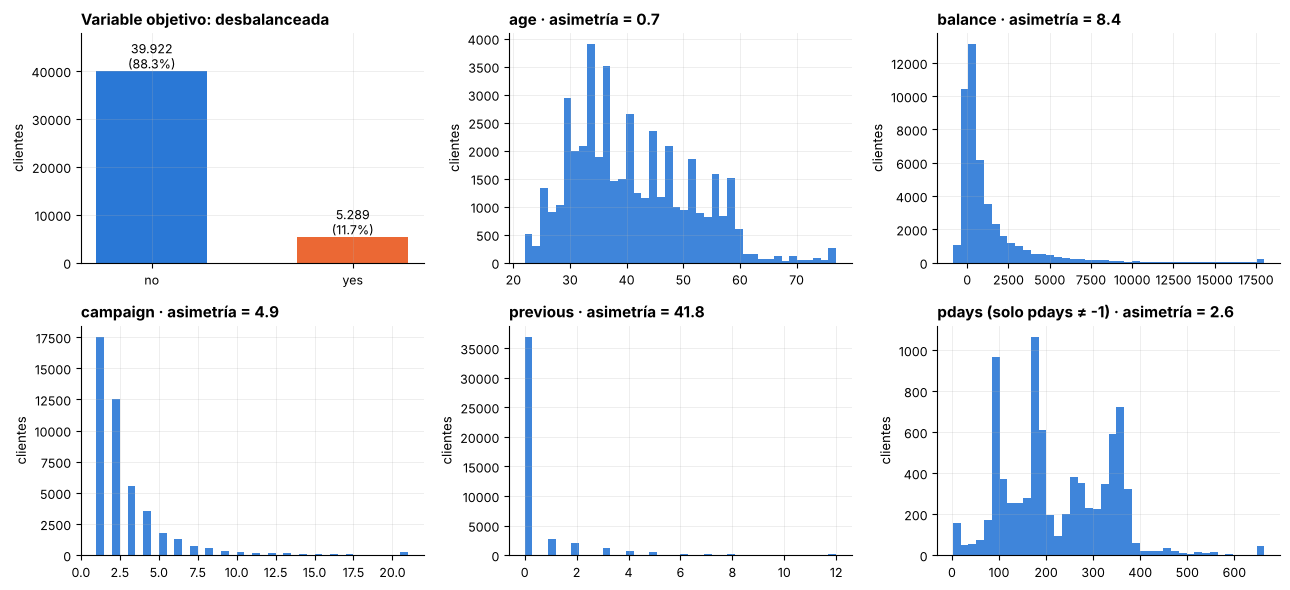

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(13, 6))
# 1) desbalance de clases
ax = axs[0, 0]
ax.bar(["no", "yes"], conteo.values, color=[COLORES[0], COLORES[1]], width=0.55)
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v:,}\n({pct.values[i]}%)".replace(",", "."), ha="center", va="bottom", fontsize=9)
ax.set_title("Variable objetivo: desbalanceada"); ax.set_ylabel("clientes"); ax.set_ylim(0, conteo.max()*1.2)
# 2-6) distribuciones numéricas
for ax, c in zip(axs.ravel()[1:], ["age", "balance", "campaign", "previous", "pdays"]):
    datos_c = df.loc[df.pdays > -1, c] if c == "pdays" else df[c]
    lo, hi = datos_c.quantile([0.005, 0.995])
    ax.hist(datos_c.clip(lo, hi), bins=40, color=COLORES[0], alpha=0.9)
    ax.set_title(f"{c}" + (" (solo pdays ≠ -1)" if c == "pdays" else "") + f" · asimetría = {df[c].skew():.1f}")
    ax.set_ylabel("clientes")
plt.tight_layout(); guardar("eda_distribuciones"); plt.show()

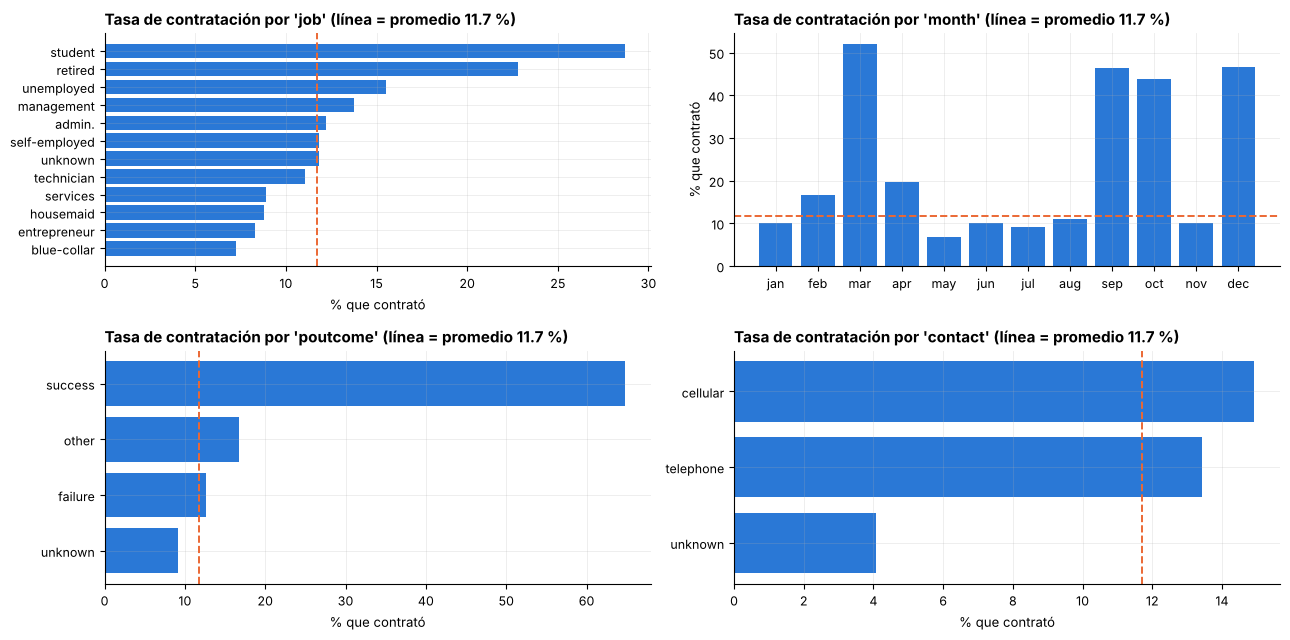

In [ ]:
# Tasa de contratación por categoría: ¿qué variables parecen informativas?
tasa_base = (df.y == "yes").mean() * 100
orden_mes = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
fig, axs = plt.subplots(2, 2, figsize=(13, 6.5))
for ax, (c, orden) in zip(axs.ravel(), [("job", None), ("month", orden_mes), ("poutcome", None), ("contact", None)]):
    t = df.groupby(c)["y"].apply(lambda s: (s == "yes").mean() * 100)
    t = t.reindex(orden) if orden else t.sort_values()
    ax.barh(t.index, t.values, color=COLORES[0]) if orden is None else ax.bar(t.index, t.values, color=COLORES[0])
    (ax.axvline if orden is None else ax.axhline)(tasa_base, color=COLORES[1], ls="--", lw=1.4)
    ax.set_title(f"Tasa de contratación por '{c}' (línea = promedio {tasa_base:.1f} %)")
    ax.set_xlabel("% que contrató") if orden is None else ax.set_ylabel("% que contrató")
plt.tight_layout(); guardar("eda_tasas"); plt.show()

### Análisis del EDA: qué vemos y qué decidimos

1. **Desbalance fuerte.** 39.922 clientes dicen "no" (88,3 %) y 5.289 "yes" (11,7 %). Consecuencia: *Accuracy* no sirve como métrica principal (un modelo que siempre responde "no" ya tendría 88,3 %). Usaremos **PR-AUC, Precision, Recall y F1** de la clase "yes", partición **estratificada**, y evaluaremos pesos de clase y ajuste del umbral.
2. **`unknown` no es un dato faltante cualquiera.** Aparece en `poutcome` (36.959 filas, 81,7 %), `contact` (13.020, 28,8 %), `education` (1.857, 4,1 %) y `job` (288, 0,6 %). Y es **informativo**: con `contact = unknown` contrata solo el 4,1 % (vs 14,9 % por celular), y con `poutcome = unknown` el 9,2 % (vs 64,7 % cuando la campaña previa fue *success*). Por eso se conserva como categoría en vez de imputarla.
3. **`pdays = -1` en el 81,7 % de las filas** (coincide exactamente con `previous = 0`): son clientes nunca contactados antes. Contratan 9,2 % frente a 23,1 % de los que sí fueron contactados antes → conviene una **bandera** explícita y no tratar el −1 como un número de días.
4. **Escalas y asimetrías muy distintas.** Asimetría (*skewness*) de `previous` = 41,8; `balance` = 8,4 (con 3.766 clientes de saldo negativo); `campaign` = 4,9; `pdays` = 2,6. En cambio `age` (0,7) y `day` (0,1) son casi simétricas. Las colas largas harían que unos pocos clientes dominen los gradientes → **transformación logarítmica** y estandarización.
5. **Hay señal, pero moderada.** La tasa de contratación varía mucho por mes (marzo 52 %, diciembre 46,7 %, septiembre 46,5 %, octubre 43,8 % vs. mayo 6,7 %; ojo: los meses de alta tasa tienen pocos clientes, p. ej. diciembre n = 214), por ocupación (estudiantes 28,7 %, jubilados 22,8 % vs. *blue-collar* 7,3 %), por edad (≤ 25 años: 24 %; > 65: 42,6 %) y por crédito hipotecario (sin hipoteca 16,7 % vs. 7,7 %). Hay patrones que aprender, pero **no esperamos un rendimiento cercano a 1**: es un problema con ruido y desbalance.

### 2.3 Decisiones de preprocesamiento y su justificación

| # | Decisión | Justificación técnica |
|---|---|---|
| 1 | **Eliminar `duration`** | La duración de la llamada solo se conoce **después** de llamar; además `duration = 0` implica siempre `"no"`. Usarla produce un modelo con **fuga de información** (*data leakage*), inútil para decidir *a quién* llamar. Los autores del dataset recomiendan excluirla para un modelo predictivo realista. Se comprueba experimentalmente en la sección 3.3. |
| 2 | **`default`, `housing`, `loan` → 0/1** | Variables binarias `yes/no`: basta una columna numérica. |
| 3 | **`job`, `marital`, `education`, `contact`, `month`, `poutcome` → One-Hot** | Son categorías **sin orden natural** (p. ej. *blue-collar* no es "mayor" que *student*). Codificarlas como 1, 2, 3… induciría un orden falso en una red que multiplica por pesos. |
| 4 | **`unknown` se conserva como una categoría más** | No hay NaN; "unknown" es información: `poutcome = unknown` equivale a "no hay campaña previa" y tiene una tasa de contratación muy distinta. Imputar con la moda destruiría esa señal. |
| 5 | **`pdays = -1` → bandera `pdays_nunca` + `pdays = 0`** | `-1` **no es un número de días**; si se deja, la red lo interpretaría como "el día más cercano posible" y distorsiona la escala (81,7 % de las filas). Se separa en (a) un indicador binario "nunca contactado" y (b) los días, con 0 cuando no aplica. |
| 6 | **`balance` → `sign(x)·log(1+|x|)`** | Va de −8.019 a 102.127 con cola muy larga y **valores negativos**: el logaritmo "puro" no sirve para negativos; la versión con signo comprime la cola conservando el orden. |
| 7 | **`campaign`, `previous`, `pdays` → `log(1+x)`** | Son conteos/días con fuerte asimetría (outliers hasta 275 contactos): sin transformar, unos pocos clientes dominarían los gradientes. |
| 8 | **`day` → seno y coseno** | El día 31 y el día 1 están *cerca* en el calendario pero lejos como números; la codificación cíclica lo respeta. |
| 9 | **`StandardScaler` (media 0, varianza 1) en las numéricas** | Las entradas a escalas distintas generan una función de costo "alargada" que el descenso del gradiente recorre en zigzag; estandarizar acelera y estabiliza la convergencia (material 1.5.1). **Se ajusta solo con entrenamiento** y se aplica a validación/prueba (evita fuga de información). |
| 10 | **Partición estratificada 70/15/15** | Conserva la proporción de clases en los tres conjuntos. |

> **Importante — fuga de información:** todo lo que el preprocesamiento "aprende" (media/desviación del escalador, categorías del One-Hot) se calcula **solo con el conjunto de entrenamiento** (`fit` en entrenamiento, `transform` en validación y prueba).

In [ ]:
MESES = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
COLS_BIN = ["default", "housing", "loan"]
COLS_CAT = ["job", "marital", "education", "contact", "month", "poutcome"]
COLS_NUM = ["age", "balance", "campaign", "pdays", "previous"]

def ingenieria(d, incluir_duration=False, normalizar=True):
    # Transformaciones por fila (no dependen de otros datos -> no hay fuga de información)
    d = d.copy()
    d["pdays_nunca"] = (d["pdays"] == -1).astype(int)          # bandera: nunca contactado antes
    d["pdays"] = d["pdays"].clip(lower=0)                      # -1 deja de ser "un número de días"
    for c in COLS_BIN:
        d[c] = (d[c] == "yes").astype(int)
    d["day_sin"] = np.sin(2 * np.pi * d["day"] / 31)           # codificación cíclica del día del mes
    d["day_cos"] = np.cos(2 * np.pi * d["day"] / 31)
    d = d.drop(columns=["day"])
    if normalizar:
        d["balance"] = np.sign(d["balance"]) * np.log1p(d["balance"].abs())   # log con signo
        for c in ["campaign", "previous", "pdays"]:
            d[c] = np.log1p(d[c])
        if incluir_duration:
            d["duration"] = np.log1p(d["duration"])
    if not incluir_duration:
        d = d.drop(columns=["duration"])
    return d

def crear_transformador(incluir_duration=False, normalizar=True):
    num = COLS_NUM + (["duration"] if incluir_duration else [])
    return ColumnTransformer(
        [("num", StandardScaler() if normalizar else "passthrough", num),
         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COLS_CAT)],
        remainder="passthrough")          # el resto (binarias, pdays_nunca, day_sin/cos) pasa tal cual

# ---------- Partición estratificada 70 / 15 / 15 (índices fijos para todo el notebook) ----------
X = df.drop(columns="y")
y = (df["y"] == "yes").astype(int).to_numpy()
idx = np.arange(len(df))
idx_tmp, idx_te = train_test_split(idx, test_size=0.15, stratify=y, random_state=SEED)
idx_tr, idx_va = train_test_split(idx_tmp, test_size=0.15 / 0.85, stratify=y[idx_tmp], random_state=SEED)

def preparar(incluir_duration=False, normalizar=True):
    # Ajusta el transformador SOLO con entrenamiento y devuelve todo lo necesario para entrenar
    f = lambda d: ingenieria(d, incluir_duration, normalizar)
    ct = crear_transformador(incluir_duration, normalizar)
    Xtr = ct.fit_transform(f(X.iloc[idx_tr])).astype("float32")
    Xva = ct.transform(f(X.iloc[idx_va])).astype("float32")
    Xte = ct.transform(f(X.iloc[idx_te])).astype("float32")
    return dict(Xtr=Xtr, Xva=Xva, Xte=Xte, ytr=y[idx_tr], yva=y[idx_va], yte=y[idx_te],
                ct=ct, f=f, nombres=list(ct.get_feature_names_out()))

def transformar(datos, d_raw):
    # aplica el preprocesamiento ya ajustado a datos crudos (para validación cruzada / importancia)
    return datos["ct"].transform(datos["f"](d_raw)).astype("float32")

datos = preparar()           # <- configuración oficial: sin duration, con transformaciones y escalado

print("Formas  X_train:", datos["Xtr"].shape, "| X_val:", datos["Xva"].shape, "| X_test:", datos["Xte"].shape)
print("Variables de entrada tras el preprocesamiento:", datos["Xtr"].shape[1])
print("NaN en X:", int(np.isnan(datos["Xtr"]).sum() + np.isnan(datos["Xva"]).sum() + np.isnan(datos["Xte"]).sum()))
tabla_split = pd.DataFrame({
    "filas": [len(idx_tr), len(idx_va), len(idx_te)],
    "% positivos (yes)": [datos["ytr"].mean()*100, datos["yva"].mean()*100, datos["yte"].mean()*100]},
    index=["entrenamiento", "validación", "prueba"]).round(2)
display(tabla_split)

Formas  X_train: (31647, 49) | X_val: (6782, 49) | X_test: (6782, 49)
Variables de entrada tras el preprocesamiento: 49
NaN en X: 0


,filas,% positivos (yes)
entrenamiento,31647,11.70
validación,6782,11.69
prueba,6782,11.69


In [ ]:
# Ejemplo concreto: una fila antes y después del preprocesamiento
ejemplo = X.iloc[[idx_tr[0]]]
print("ANTES (fila cruda):")
display(ejemplo.T.rename(columns={ejemplo.index[0]: "valor"}).T)
print("DESPUÉS (vector que recibe la red, solo columnas distintas de cero y las numéricas):")
vec = pd.Series(datos["Xtr"][0], index=datos["nombres"])
display(vec[(vec != 0) | vec.index.str.contains("num__")].round(3).to_frame("valor").T)

# Verificación: el escalador se ajustó con entrenamiento -> media≈0, desv≈1 en train (en val/test solo aproximado)
num_idx = [i for i, n in enumerate(datos["nombres"]) if n.startswith("num__")]
verif = pd.DataFrame({
    "media train": datos["Xtr"][:, num_idx].mean(0), "desv. train": datos["Xtr"][:, num_idx].std(0),
    "media val": datos["Xva"][:, num_idx].mean(0), "desv. val": datos["Xva"][:, num_idx].std(0)},
    index=[datos["nombres"][i] for i in num_idx]).round(3)
display(verif)

ANTES (fila cruda):


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
valor,36,management,single,tertiary,no,391,no,no,unknown,18,jun,443,1,-1,0,unknown


DESPUÉS (vector que recibe la red, solo columnas distintas de cero y las numéricas):


,num__age,num__balance,num__campaign,num__pdays,num__previous,cat__job_management,cat__marital_single,cat__education_tertiary,cat__contact_unknown,cat__month_jun,cat__poutcome_unknown,remainder__pdays_nunca,remainder__day_sin,remainder__day_cos
valor,-0.464,0.286,-0.909,-0.467,-0.424,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-0.485,-0.874


,media train,desv. train,media val,desv. val
num__age,0.0,1.0,-0.021,0.987
num__balance,-0.0,1.0,0.010,0.984
num__campaign,-0.0,1.0,-0.003,0.991
num__pdays,-0.0,1.0,0.004,1.003
num__previous,-0.0,1.0,0.008,1.018


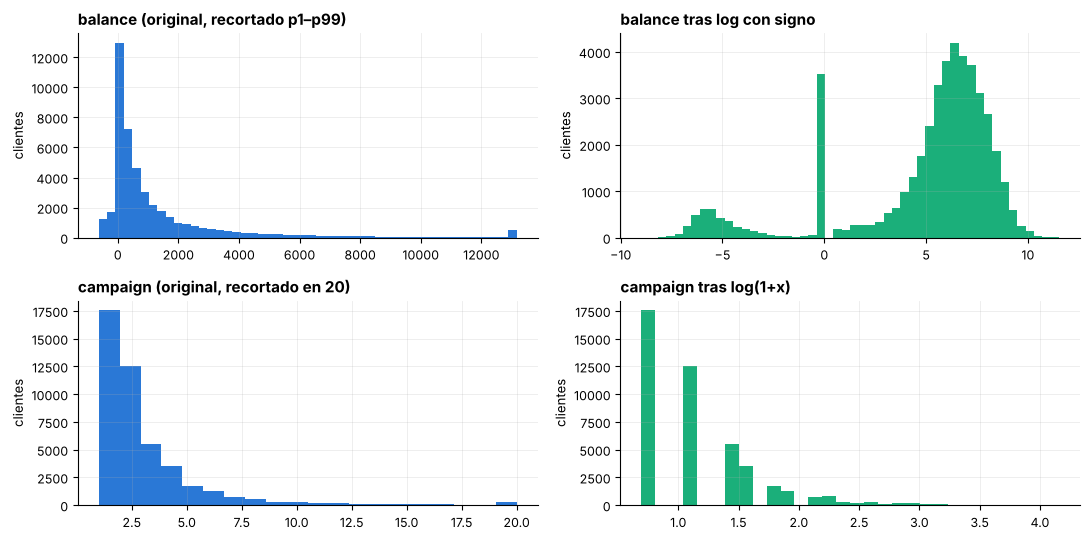

In [ ]:
# Efecto visual de las transformaciones sobre las variables más sesgadas
fig, axs = plt.subplots(2, 2, figsize=(11, 5.5))
bal_t = np.sign(df.balance) * np.log1p(df.balance.abs())
lo, hi = df.balance.quantile([0.01, 0.99])
axs[0, 0].hist(df.balance.clip(lo, hi), bins=50, color=COLORES[0]); axs[0, 0].set_title("balance (original, recortado p1–p99)")
axs[0, 1].hist(bal_t, bins=50, color=COLORES[2]); axs[0, 1].set_title("balance tras log con signo")
axs[1, 0].hist(df.campaign.clip(upper=20), bins=20, color=COLORES[0]); axs[1, 0].set_title("campaign (original, recortado en 20)")
axs[1, 1].hist(np.log1p(df.campaign), bins=30, color=COLORES[2]); axs[1, 1].set_title("campaign tras log(1+x)")
for a in axs.ravel(): a.set_ylabel("clientes")
plt.tight_layout(); guardar("prep_transformaciones"); plt.show()

## 3. Definición del modelo (MLP) y herramientas de experimentación

### 3.1 Arquitectura: qué es y por qué
Un **MLP** (*Multi-Layer Perceptron*) apila capas `Dense`: cada neurona calcula la suma ponderada $u = \sum_i w_i x_i + b$ y le aplica una **función de activación no lineal** (sin no linealidad, apilar capas equivale a una sola capa y solo se separarían clases linealmente; material 1.2.1). La red aprende los pesos $w, b$ minimizando una **función de pérdida** con **descenso del gradiente**, donde **backpropagation** calcula las derivadas con la regla de la cadena (material 1.3.1 y 1.4.1).

**Configuración base (punto de partida de todos los experimentos controlados):**

| Elemento | Valor base | Justificación |
|---|---|---|
| Entrada | 49 variables (tras One-Hot) | Resultado del preprocesamiento |
| Capas ocultas | 2 capas: **64 → 32** neuronas | Dataset tabular de ~32 mil filas y 49 variables: una red pequeña basta. Embudo decreciente (de más a menos neuronas) que va condensando representaciones. Se contrastará con otras profundidades en la sección 4.6 |
| Activación oculta | **ReLU** | No se satura para valores positivos → gradiente no desaparece; es barata de calcular y es la usada hoy en día (material 1.2.1 y 1.6.1). Se compara con otras en la sección 5 |
| Capa de salida | **1 neurona + sigmoide** | Clasificación binaria: la sigmoide entrega un número en (0,1) interpretable como $P(y=\text{yes})$ |
| Pérdida | **Entropía cruzada binaria** | Es la log-verosimilitud negativa de un modelo Bernoulli; penaliza mucho las predicciones seguras y erradas. Se compara con MSE, pesos de clase, *focal loss* y softmax en la sección 5 |
| Optimizador | **Adam**, $\lambda=10^{-3}$ | Tasa de aprendizaje adaptativa por parámetro; punto de partida estándar (material 1.6.1). Se compara en la sección 6 |
| Batch / épocas | 256 / 40 | Compromiso entre ruido del gradiente y velocidad; se justifica con experimentos en la sección 4 |
| Inicialización | Glorot uniforme (por defecto de Keras) | Se compara con otras en la sección 6.3 |

### 3.2 Funciones de apoyo
Todo el código de experimentación está **modularizado** en estas celdas: construir el modelo, entrenarlo con varias semillas, calcular métricas, tabular y graficar. Así cada experimento posterior es una sola llamada y cambia **solo un parámetro**.

In [ ]:
# ============================================================
# Métricas
# ============================================================
def umbral_optimo(y_real, p):
    # Umbral de decisión que maximiza el F1 de la clase positiva (se calcula SIEMPRE sobre validación)
    pr, rc, th = precision_recall_curve(y_real, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    i = int(np.nanargmax(f1[:-1]))
    return float(th[i]), float(f1[i])

def metricas(y_real, p, umbral=0.5):
    yhat = (p >= umbral).astype(int)
    return {"accuracy": accuracy_score(y_real, yhat),
            "precision": precision_score(y_real, yhat, zero_division=0),
            "recall": recall_score(y_real, yhat, zero_division=0),
            "f1": f1_score(y_real, yhat, zero_division=0),
            "pr_auc": average_precision_score(y_real, p),
            "roc_auc": roc_auc_score(y_real, p)}

def proba(modelo, Xm, salida="sigmoid"):
    out = modelo(Xm, training=False).numpy()
    return out[:, 1] if salida == "softmax" else out.ravel()

# ============================================================
# Construcción del MLP (todas las variantes del notebook salen de esta función)
# ============================================================
def crear_optimizador(nombre, lr):
    return {"sgd": lambda: keras.optimizers.SGD(lr),
            "sgd_momentum": lambda: keras.optimizers.SGD(lr, momentum=0.9),
            "sgd_nesterov": lambda: keras.optimizers.SGD(lr, momentum=0.9, nesterov=True),
            "adagrad": lambda: keras.optimizers.Adagrad(lr),
            "rmsprop": lambda: keras.optimizers.RMSprop(lr),
            "adam": lambda: keras.optimizers.Adam(lr)}[nombre]()

def crear_perdida(nombre):
    if nombre == "focal":
        return keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=0.75, gamma=2.0)
    return nombre

def crear_init(nombre):
    if nombre == "normal_std1":
        return keras.initializers.RandomNormal(mean=0.0, stddev=1.0)
    return nombre

def construir_mlp(n_in, capas=(64, 32), activacion="relu", salida="sigmoid", dropout=0.0, l2=0.0,
                  batchnorm=False, init="glorot_uniform", optimizador="adam", lr=LR,
                  perdida="binary_crossentropy"):
    reg = regularizers.l2(l2) if l2 > 0 else None
    m = keras.Sequential([layers.Input((n_in,))])
    for u in capas:
        m.add(layers.Dense(u, kernel_initializer=crear_init(init), kernel_regularizer=reg))
        if batchnorm:
            m.add(layers.BatchNormalization())      # entre la neurona y la activación (material 1.5.1)
        m.add(layers.Activation(activacion))
        if dropout > 0:
            m.add(layers.Dropout(dropout))          # solo actúa en entrenamiento
    m.add(layers.Dense(1, activation="sigmoid") if salida == "sigmoid" else layers.Dense(2, activation="softmax"))
    m.compile(optimizer=crear_optimizador(optimizador, lr), loss=crear_perdida(perdida))
    return m

# ============================================================
# Callback: métricas de validación por época + parada temprana opcional
# ============================================================
class ControlVal(keras.callbacks.Callback):
    def __init__(self, Xva, yva, salida="sigmoid", monitor=None, paciencia=5):
        super().__init__()
        self.Xva, self.yva, self.salida, self.monitor, self.paciencia = tf.constant(Xva), yva, salida, monitor, paciencia
        self.hist = {"val_pr_auc": [], "val_f1_05": [], "val_f1_max": []}
        self.mejor, self.mejor_epoca, self.pesos, self.espera = None, 0, None, 0

    def on_epoch_end(self, epoch, logs=None):
        p = proba(self.model, self.Xva, self.salida)
        self.hist["val_pr_auc"].append(average_precision_score(self.yva, p))
        self.hist["val_f1_05"].append(f1_score(self.yva, (p >= 0.5).astype(int), zero_division=0))
        self.hist["val_f1_max"].append(umbral_optimo(self.yva, p)[1])
        if self.monitor:                                   # parada temprana (Early Stopping)
            v = logs["val_loss"] if self.monitor == "val_loss" else self.hist["val_pr_auc"][-1]
            mejora = (self.mejor is None) or (v < self.mejor if self.monitor == "val_loss" else v > self.mejor)
            if mejora:
                self.mejor, self.mejor_epoca, self.pesos, self.espera = v, epoch + 1, self.model.get_weights(), 0
            else:
                self.espera += 1
                if self.espera >= self.paciencia:
                    self.model.stop_training = True

    def on_train_end(self, logs=None):
        if self.monitor and self.pesos is not None:        # restaura los mejores pesos
            self.model.set_weights(self.pesos)

def entrenar(dat, cfg, seed, epochs=None, batch=None, pesos=False, monitor=None, paciencia=5):
    # Entrena UN modelo con una semilla. Devuelve (modelo, historial, prob. de validación, segundos, mejor época)
    epochs = epochs or EPOCHS
    batch = batch or BATCH
    keras.utils.set_random_seed(seed)
    salida = cfg.get("salida", "sigmoid")
    modelo = construir_mlp(dat["Xtr"].shape[1], **cfg)
    ctrl = ControlVal(dat["Xva"], dat["yva"], salida, monitor, paciencia)
    cw = None
    if pesos:
        neg, pos = np.bincount(dat["ytr"])
        cw = {0: 1.0, 1: neg / pos}                        # clase minoritaria pesa ~7,5 veces más
    ytr = dat["ytr"] if salida == "softmax" else dat["ytr"].astype("float32")
    yva = dat["yva"] if salida == "softmax" else dat["yva"].astype("float32")
    t = time.time()
    h = modelo.fit(dat["Xtr"], ytr, validation_data=(dat["Xva"], yva), epochs=epochs, batch_size=batch,
                   class_weight=cw, callbacks=[ctrl], verbose=0)
    dur = time.time() - t
    hist = {**h.history, **ctrl.hist}
    mejor_ep = ctrl.mejor_epoca if monitor else int(np.argmin(hist["val_loss"])) + 1
    return modelo, hist, proba(modelo, dat["Xva"], salida), dur, mejor_ep

def correr(nombre, cfg, dat=None, seeds=None, **kw):
    # Repite el entrenamiento con varias semillas y resume (media ± desv.) sobre VALIDACIÓN
    dat = dat if dat is not None else datos
    seeds = seeds or SEEDS
    hists, filas = [], []
    for s in seeds:
        m, h, p, dur, be = entrenar(dat, cfg, s, **kw)
        met = metricas(dat["yva"], p)
        thr, f1o = umbral_optimo(dat["yva"], p)
        filas.append({**met, "f1_opt": f1o, "umbral_opt": thr, "val_loss": h["val_loss"][-1],
                      "tiempo_s": dur, "epocas": len(h["loss"]), "mejor_epoca": be})
        hists.append(h)
        keras.backend.clear_session()
    print(f"  · {nombre:<28} PR-AUC={np.mean([f['pr_auc'] for f in filas]):.3f}  "
          f"F1*={np.mean([f['f1_opt'] for f in filas]):.3f}  ({time.time()-T0:,.0f}s acumulados)")
    return {"nombre": nombre, "cfg": cfg, "hist": hists, "filas": pd.DataFrame(filas), "kw": kw}

# ============================================================
# Tablas y gráficos comparativos
# ============================================================
def tabla(res_list, clave=None):
    filas = []
    for r in res_list:
        f = r["filas"]
        filas.append({"configuración": r["nombre"], "Accuracy": f.accuracy.mean(), "Precision": f.precision.mean(),
                      "Recall": f.recall.mean(), "F1 (umbral 0.5)": f.f1.mean(), "F1 (umbral óptimo)": f.f1_opt.mean(),
                      "PR-AUC": f.pr_auc.mean(), "± PR-AUC": f.pr_auc.std(ddof=0), "ROC-AUC": f.roc_auc.mean(),
                      "val_loss": f.val_loss.mean(), "épocas": f.epocas.mean(), "tiempo (s)": f.tiempo_s.mean()})
    t = pd.DataFrame(filas).set_index("configuración")
    if clave:
        RESULTADOS[clave] = json.loads(t.round(4).to_json(orient="index"))
    return t.round(3)

def media_curva(hists, clave):
    L = max(len(h[clave]) for h in hists)
    M = np.full((len(hists), L), np.nan)
    for i, h in enumerate(hists):
        M[i, :len(h[clave])] = h[clave]
    return np.nanmean(M, 0), np.nanstd(M, 0)

PANELES_STD = (("loss", "Pérdida de entrenamiento"), ("val_loss", "Pérdida de validación"), ("val_pr_auc", "PR-AUC en validación"))

def grafico_curvas(res_list, titulo, fig_nombre, paneles=PANELES_STD, logy=False):
    fig, axs = plt.subplots(1, len(paneles), figsize=(4.6 * len(paneles), 3.9))
    axs = np.atleast_1d(axs)
    for ax, (clave, tit) in zip(axs, paneles):
        for i, r in enumerate(res_list):
            m, s = media_curva(r["hist"], clave)
            x = np.arange(1, len(m) + 1)
            ax.plot(x, m, color=COLORES[i % 8], label=r["nombre"])
            ax.fill_between(x, m - s, m + s, color=COLORES[i % 8], alpha=0.15, lw=0)
        ax.set_title(tit); ax.set_xlabel("época")
        if logy and "loss" in clave: ax.set_yscale("log")
    h, l = axs[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=min(len(l), 5), bbox_to_anchor=(0.5, -0.07))
    fig.suptitle(titulo, x=0.01, ha="left", fontweight="bold", fontsize=12)
    plt.tight_layout(); guardar(fig_nombre); plt.show()

def grafico_barras(res_list, titulo, fig_nombre, rot=20):
    # PR-AUC y F1 óptimo (umbral-independiente y mejor caso) + Precision/Recall al umbral 0.5
    nombres = [r["nombre"] for r in res_list]
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, (col, tit) in zip(axs[:2], [("pr_auc", "PR-AUC (validación)"), ("f1_opt", "F1 con umbral óptimo (validación)")]):
        m = [r["filas"][col].mean() for r in res_list]; s = [r["filas"][col].std(ddof=0) for r in res_list]
        ax.bar(nombres, m, yerr=s, color=COLORES[0], capsize=3, width=0.6, error_kw={"lw": 1})
        for i, v in enumerate(m): ax.text(i, v + 0.004, f"{v:.3f}", ha="center", fontsize=8.5)
        ax.set_title(tit); ax.set_ylim(min(m) * 0.8, max(m) * 1.08); ax.tick_params(axis="x", rotation=rot)
    ax = axs[2]; w = 0.27; xs = np.arange(len(nombres))
    for k, (col, lab) in enumerate([("precision", "Precision"), ("recall", "Recall"), ("f1", "F1")]):
        ax.bar(xs + (k - 1) * w, [r["filas"][col].mean() for r in res_list], w, label=lab, color=COLORES[[0, 1, 2][k]])
    ax.set_xticks(xs); ax.set_xticklabels(nombres, rotation=rot); ax.set_title("Precision / Recall / F1 con umbral 0.5"); ax.legend(ncol=3)
    fig.suptitle(titulo, x=0.01, ha="left", fontweight="bold", fontsize=12)
    plt.tight_layout(); guardar(fig_nombre); plt.show()

# Prueba rápida de que todo funciona (1 época)
_m, _h, _p, _d, _ = entrenar(datos, {}, SEED, epochs=1)
print("Prueba OK ->", {k: round(v, 3) for k, v in metricas(datos["yva"], _p).items()}); _m.summary()
keras.backend.clear_session()

Prueba OK -> {'accuracy': 0.891, 'precision': 0.755, 'recall': 0.097, 'f1': 0.172, 'pr_auc': 0.383, 'roc_auc': 0.756}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,941 (62.27 KB)

 Trainable params: 5,313 (20.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,628 (41.52 KB)

### 3.3 Experimentos de apoyo al preprocesamiento (¿importan realmente las decisiones de la sección 2?)
La rúbrica pide justificar con evidencia. Probamos dos de las decisiones más discutibles **cambiando una a la vez** respecto de la configuración oficial:

* **A. Incluir `duration`** (versión "con fuga de información").
* **B. No transformar ni escalar** las variables numéricas (se dejan en sus unidades originales).

Experimentos de apoyo al preprocesamiento


  · Oficial (sin duration, escalado) PR-AUC=0.433  F1*=0.472  (55s acumulados)


  · A. Con 'duration'            PR-AUC=0.591  F1*=0.619  (100s acumulados)


  · B. Sin escalar ni log        PR-AUC=0.303  F1*=0.343  (149s acumulados)


,Accuracy,Precision,Recall,F1 (umbral 0.5),F1 (umbral óptimo),PR-AUC,± PR-AUC,ROC-AUC,val_loss,épocas,tiempo (s)
configuración,,,,,,,,,,,
"Oficial (sin duration, escalado)",0.894,0.596,0.282,0.382,0.472,0.433,0.002,0.792,0.294,40.0,16.090
A. Con 'duration',0.904,0.604,0.530,0.564,0.619,0.591,0.003,0.927,0.214,40.0,14.693
B. Sin escalar ni log,0.888,0.621,0.108,0.183,0.343,0.303,0.034,0.636,0.537,40.0,15.820


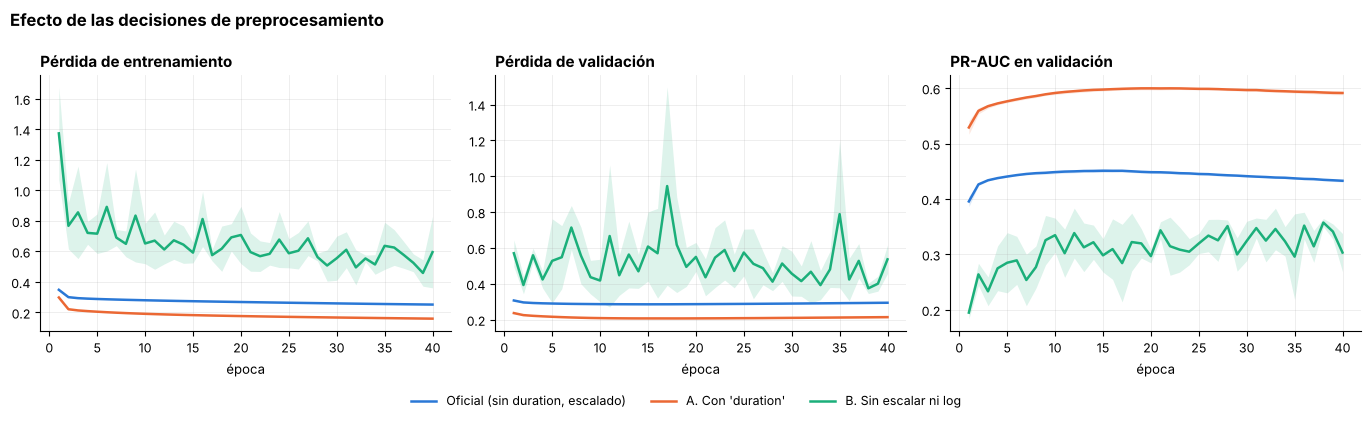

In [ ]:
print("Experimentos de apoyo al preprocesamiento")
dat_dur = preparar(incluir_duration=True)
dat_raw = preparar(normalizar=False)
r_prep = [
    correr("Oficial (sin duration, escalado)", {}, datos),
    correr("A. Con 'duration'", {}, dat_dur),
    correr("B. Sin escalar ni log", {}, dat_raw),
]
display(tabla(r_prep, "preprocesamiento"))
grafico_curvas(r_prep, "Efecto de las decisiones de preprocesamiento", "prep_experimento")

### Análisis: ¿importaron las decisiones de preprocesamiento? (media de 3 semillas, validación)

| Variante | PR-AUC | F1 (umbral óptimo) | ROC-AUC | Recall (umbral 0.5) | Desv. PR-AUC entre semillas |
|---|---|---|---|---|---|
| **Oficial** (sin `duration`, con log y escalado) | **0,433** | **0,472** | 0,792 | 0,282 | 0,002 |
| A. Con `duration` | 0,591 | 0,619 | 0,927 | 0,530 | 0,003 |
| B. Sin escalar ni log | 0,303 | 0,343 | 0,636 | 0,108 | 0,034 |

* **A — `duration` "mejora" el PR-AUC en +0,158 y el ROC-AUC llega a 0,927.** Es una mejora *ficticia*: la duración de la llamada es en gran parte **consecuencia** del interés del cliente (si quiere contratar, conversa más). Un modelo que la usa solo puede aplicarse *después* de llamar, cuando ya no sirve para decidir a quién llamar. La evidencia confirma la decisión conceptual: **se excluye `duration`** y el modelo oficial es el más honesto, no el de mayor puntaje.
* **B — Sin transformar ni escalar, el rendimiento se desploma**: PR-AUC 0,303 (−0,130), ROC-AUC 0,636, pérdida de validación 0,537 (vs. 0,294) y el resultado se vuelve **inestable** (desv. 0,034 vs. 0,002). Con `balance` en miles de euros junto a variables de escala 0–1, las neuronas reciben entradas enormes que saturan las activaciones y desbalancean los gradientes: la función de costo queda "alargada" y el descenso del gradiente avanza en zigzag (material 1.5.1). Esto **valida las decisiones 6, 7 y 9** de la sección 2.3.

## 4. Entrenamiento: parámetros clave y experimentos controlados

### 4.1 Cómo se hace un experimento controlado
Partimos de la **configuración base** (64→32, ReLU, BCE, Adam, `lr=1e-3`, `batch=256`, `épocas=40`) y **variamos un parámetro por vez**, repitiendo con `N_SEEDS` semillas. Cualquier diferencia se puede atribuir a ese parámetro. Se muestran curvas (media ± desviación) y tablas.

### 4.2 Línea base

In [ ]:
print("Configuración base")
r_base = correr("Base (lr=1e-3, batch=256)", {})
display(tabla([r_base], "base"))

Configuración base


  · Base (lr=1e-3, batch=256)    PR-AUC=0.433  F1*=0.472  (195s acumulados)


,Accuracy,Precision,Recall,F1 (umbral 0.5),F1 (umbral óptimo),PR-AUC,± PR-AUC,ROC-AUC,val_loss,épocas,tiempo (s)
configuración,,,,,,,,,,,
"Base (lr=1e-3, batch=256)",0.894,0.596,0.282,0.382,0.472,0.433,0.002,0.792,0.294,40.0,14.952


### 4.3 Parámetro 1 — Número de épocas
Una **época** es una pasada completa por los datos de entrenamiento. Pocas épocas → *subajuste* (la red no ha aprendido los patrones); demasiadas → *sobreajuste* (memoriza ruido y la validación empeora; material 1.5.1). Para ver ambos regímenes entrenamos la configuración base durante **150 épocas** y miramos cómo evolucionan entrenamiento y validación.

Experimento: número de épocas (150 épocas, configuración base)


  · Base 150 épocas              PR-AUC=0.372  F1*=0.422  (365s acumulados)


,pérdida train,pérdida val,PR-AUC val,F1 val (0.5),F1 val (óptimo)
época,,,,,
1,0.349,0.307,0.396,0.163,0.416
5,0.288,0.290,0.441,0.317,0.479
10,0.280,0.287,0.449,0.344,0.488
20,0.269,0.287,0.448,0.364,0.486
40,0.252,0.294,0.433,0.382,0.472
80,0.229,0.316,0.403,0.382,0.449
150,0.206,0.353,0.372,0.369,0.422


Época con menor pérdida de validación (media de 3 semillas): 15


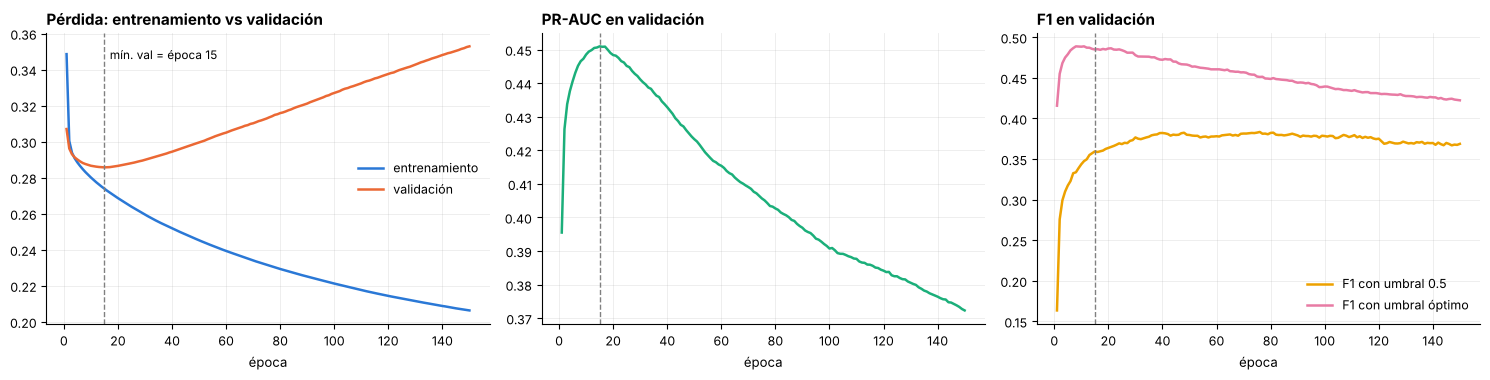

In [ ]:
print("Experimento: número de épocas (150 épocas, configuración base)")
r_ep = correr("Base 150 épocas", {}, epochs=150)
h = r_ep["hist"]
tr, _ = media_curva(h, "loss"); va, _ = media_curva(h, "val_loss")
pr, _ = media_curva(h, "val_pr_auc"); f05, _ = media_curva(h, "val_f1_05"); fmx, _ = media_curva(h, "val_f1_max")
mejor_ep = int(np.argmin(va)) + 1
cortes = [1, 5, 10, 20, 40, 80, 150]
tab_ep = pd.DataFrame({"pérdida train": tr[[c-1 for c in cortes]], "pérdida val": va[[c-1 for c in cortes]],
                       "PR-AUC val": pr[[c-1 for c in cortes]], "F1 val (0.5)": f05[[c-1 for c in cortes]],
                       "F1 val (óptimo)": fmx[[c-1 for c in cortes]]}, index=pd.Index(cortes, name="época")).round(3)
display(tab_ep)
print(f"Época con menor pérdida de validación (media de {N_SEEDS} semillas): {mejor_ep}")
RESULTADOS["epocas"] = {"tabla": json.loads(tab_ep.to_json(orient="index")), "mejor_epoca_val_loss": mejor_ep}

fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
x = np.arange(1, len(tr) + 1)
axs[0].plot(x, tr, label="entrenamiento", color=COLORES[0]); axs[0].plot(x, va, label="validación", color=COLORES[1])
axs[0].axvline(mejor_ep, color="gray", ls="--", lw=1); axs[0].text(mejor_ep + 2, va.max()*0.98, f"mín. val = época {mejor_ep}", fontsize=8.5)
axs[0].set_title("Pérdida: entrenamiento vs validación"); axs[0].set_xlabel("época"); axs[0].legend()
axs[1].plot(x, pr, color=COLORES[2]); axs[1].axvline(mejor_ep, color="gray", ls="--", lw=1)
axs[1].set_title("PR-AUC en validación"); axs[1].set_xlabel("época")
axs[2].plot(x, f05, label="F1 con umbral 0.5", color=COLORES[3]); axs[2].plot(x, fmx, label="F1 con umbral óptimo", color=COLORES[4])
axs[2].axvline(mejor_ep, color="gray", ls="--", lw=1); axs[2].set_title("F1 en validación"); axs[2].set_xlabel("época"); axs[2].legend()
plt.tight_layout(); guardar("param_epocas"); plt.show()

### Análisis: número de épocas

| Época | Pérdida train | Pérdida val | PR-AUC val | F1 val (0.5) | F1 val (óptimo) |
|---|---|---|---|---|---|
| 1 | 0,349 | 0,307 | 0,396 | 0,163 | 0,416 |
| 5 | 0,288 | 0,290 | 0,441 | 0,317 | 0,479 |
| 10 | 0,280 | 0,287 | 0,449 | 0,344 | 0,488 |
| 20 | 0,269 | 0,287 | 0,448 | 0,364 | 0,486 |
| 40 | 0,252 | 0,294 | 0,433 | 0,382 | 0,472 |
| 80 | 0,229 | 0,316 | 0,403 | 0,382 | 0,449 |
| 150 | 0,206 | 0,353 | 0,372 | 0,369 | 0,422 |

* **Tres regímenes claros.** *Subajuste* en las primeras ~5 épocas (la pérdida de validación aún baja); *punto óptimo* hacia las **épocas 10–20** (la pérdida de validación es mínima en la época **15** y el PR-AUC alcanza su máximo, ≈ 0,45); y **sobreajuste** después: la pérdida de entrenamiento sigue bajando (0,252 → 0,206) mientras la de validación **sube** (0,294 → 0,353) y el PR-AUC cae de 0,449 a 0,372. La brecha creciente entre ambas curvas es la firma del sobreajuste (material 1.5.1).
* **Una trampa instructiva:** el F1 con umbral 0,5 *sube* hasta la época ~40 (0,382) mientras la capacidad de **ordenar** clientes (PR-AUC y F1 con umbral óptimo) ya está empeorando. Al sobreentrenar, la red da probabilidades más extremas y el corte 0,5 "casualmente" se acerca mejor al punto de equilibrio. Moraleja: **no juzgar un modelo solo por métricas a umbral fijo**.
* **Decisión:** la configuración base (40 épocas) ya está pasada del óptimo (≈ 15). En lugar de fijar las épocas "a ojo", el modelo final usará **Early Stopping** (máx. 60 épocas, paciencia 6, restaurando los mejores pesos). Para los demás experimentos controlados se mantienen 40 épocas **a propósito**, para que todas las variantes se comparen con el mismo presupuesto; pero hay que recordar que, a épocas fijas, cada parámetro también cambia *qué tan rápido* se sobreajusta la red.

### 4.4 Parámetro 2 — Tasa de aprendizaje (*learning rate*)
Es el tamaño del paso del descenso del gradiente: $\theta \leftarrow \theta - \lambda \nabla L$. Material 1.3.1 (tamaño de paso) y 1.6.1 (*learning rate*): *muy pequeña* → la red tarda "siglos"; *muy grande* → comportamiento errático como una pelota de pinball, puede no converger. Probamos $\lambda \in \{10^{-4}, 10^{-3}, 10^{-2}, 10^{-1}\}$ con Adam.

Experimento: tasa de aprendizaje


  · lr = 0.0001                  PR-AUC=0.441  F1*=0.479  (414s acumulados)


  · lr = 0.01                    PR-AUC=0.338  F1*=0.407  (465s acumulados)


  · lr = 0.1                     PR-AUC=0.379  F1*=0.469  (515s acumulados)


,Accuracy,Precision,Recall,F1 (umbral 0.5),F1 (umbral óptimo),PR-AUC,± PR-AUC,ROC-AUC,val_loss,épocas,tiempo (s)
configuración,,,,,,,,,,,
lr = 0.0001,0.893,0.634,0.210,0.315,0.479,0.441,0.002,0.790,0.290,40.0,15.498
lr = 0.001 (base),0.894,0.596,0.282,0.382,0.472,0.433,0.002,0.792,0.294,40.0,14.952
lr = 0.01,0.880,0.478,0.256,0.333,0.407,0.338,0.014,0.725,0.407,40.0,16.557
lr = 0.1,0.888,0.388,0.210,0.263,0.469,0.379,0.043,0.774,0.305,40.0,16.169


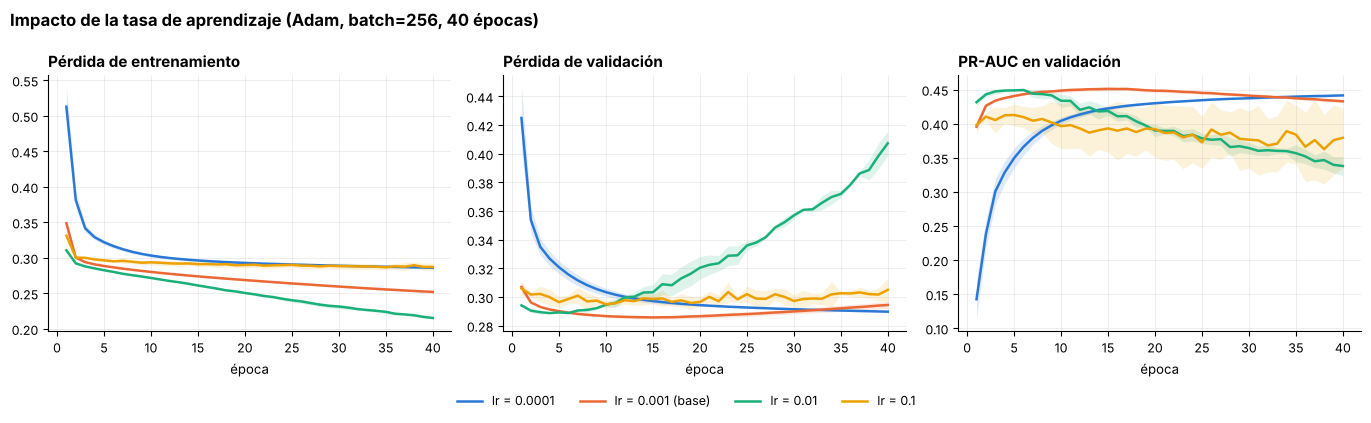

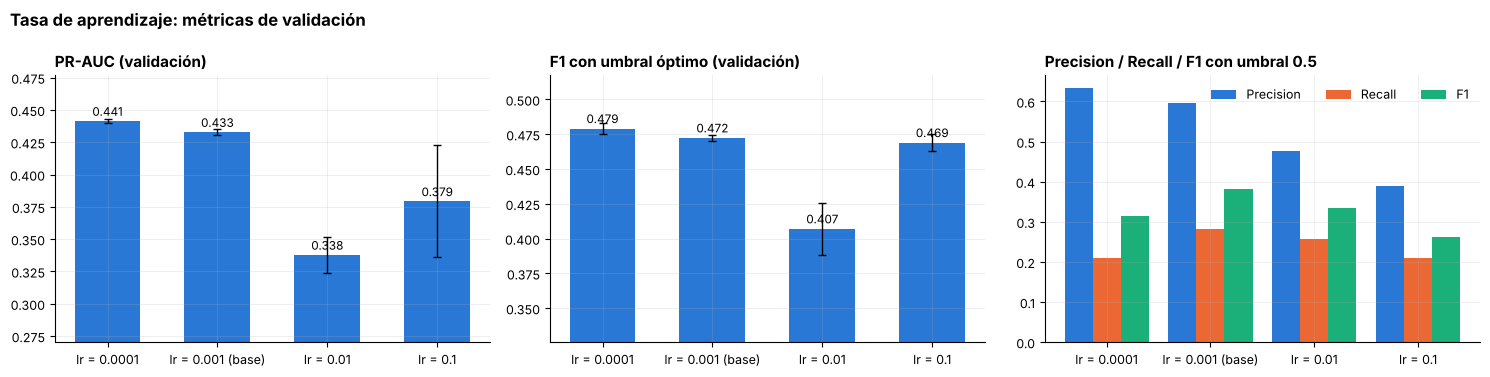

In [ ]:
print("Experimento: tasa de aprendizaje")
r_lr = [correr(f"lr = {lr:g}", {"lr": lr}) if lr != 1e-3 else {**r_base, "nombre": "lr = 0.001 (base)"} for lr in [1e-4, 1e-3, 1e-2, 1e-1]]
display(tabla(r_lr, "lr"))
grafico_curvas(r_lr, "Impacto de la tasa de aprendizaje (Adam, batch=256, 40 épocas)", "param_lr")
grafico_barras(r_lr, "Tasa de aprendizaje: métricas de validación", "param_lr_barras", rot=0)

### Análisis: tasa de aprendizaje (Adam, 40 épocas, media de 3 semillas)

| lr | PR-AUC | ± | F1 óptimo | Recall (0.5) | Pérdida val |
|---|---|---|---|---|---|
| 1e-4 | 0,441 | 0,002 | 0,479 | 0,210 | 0,290 |
| **1e-3 (base)** | 0,433 | 0,002 | 0,472 | 0,282 | 0,294 |
| 1e-2 | 0,338 | 0,014 | 0,407 | 0,256 | 0,407 |
| 1e-1 | 0,379 | 0,043 | 0,469 | 0,210 | 0,305 |

* **lr = 1e-2 y 1e-1 son claramente peores** (PR-AUC 0,338 y 0,379; pérdida de validación 0,407 en el primero) y **menos estables**: la desviación entre semillas es 0,014 y 0,043 vs. 0,002 con lr ≤ 1e-3. Con pasos grandes el descenso del gradiente "rebota" alrededor del mínimo y a veces no converge (material 1.6.1: *"pelota de pinball"*).
* **lr = 1e-4 es ligeramente mejor que 1e-3 con 40 épocas** (0,441 vs 0,433). No es porque "aprenda mejor", sino porque aprende más despacio: en la sección 4.3 vimos que a las 40 épocas la red base ya sobreajusta; con paso pequeño llega a ese punto más tarde. Es decir, *a épocas fijas, lr y épocas están confundidos*.
* **Decisión:** usar **lr = 1e-3** con Early Stopping: es la zona estable, aprende rápido (óptimo en ~15–20 épocas) y el Early Stopping elimina el problema de "cuántas épocas". La búsqueda de la sección 7 vuelve a explorar {3e-4, 1e-3, 3e-3}.

### 4.5 Parámetro 3 — Tamaño de batch
El **descenso del gradiente estocástico por mini-lotes** estima el gradiente con un subconjunto aleatorio de datos (material 1.3.1). Batch pequeño → gradiente ruidoso pero muchas actualizaciones por época (efecto regularizador, más lento por época); batch grande → gradiente más preciso, menos actualizaciones, más rápido por época. Con épocas fijas, un batch grande hace **menos pasos totales**. Probamos $\{32, 128, 256, 1024\}$.

Experimento: tamaño de batch


  · batch = 32                   PR-AUC=0.387  F1*=0.432  (757s acumulados)


  · batch = 128                  PR-AUC=0.423  F1*=0.472  (833s acumulados)


  · batch = 1024                 PR-AUC=0.454  F1*=0.489  (860s acumulados)


,Accuracy,Precision,Recall,F1 (umbral 0.5),F1 (umbral óptimo),PR-AUC,± PR-AUC,ROC-AUC,val_loss,épocas,tiempo (s),actualizaciones/época
configuración,,,,,,,,,,,,
batch = 32,0.888,0.546,0.256,0.348,0.432,0.387,0.006,0.767,0.325,40.0,79.896,989
batch = 128,0.893,0.592,0.285,0.385,0.472,0.423,0.011,0.787,0.300,40.0,24.928,248
batch = 256 (base),0.894,0.596,0.282,0.382,0.472,0.433,0.002,0.792,0.294,40.0,14.952,124
batch = 1024,0.895,0.618,0.266,0.371,0.489,0.454,0.002,0.799,0.285,40.0,8.365,31


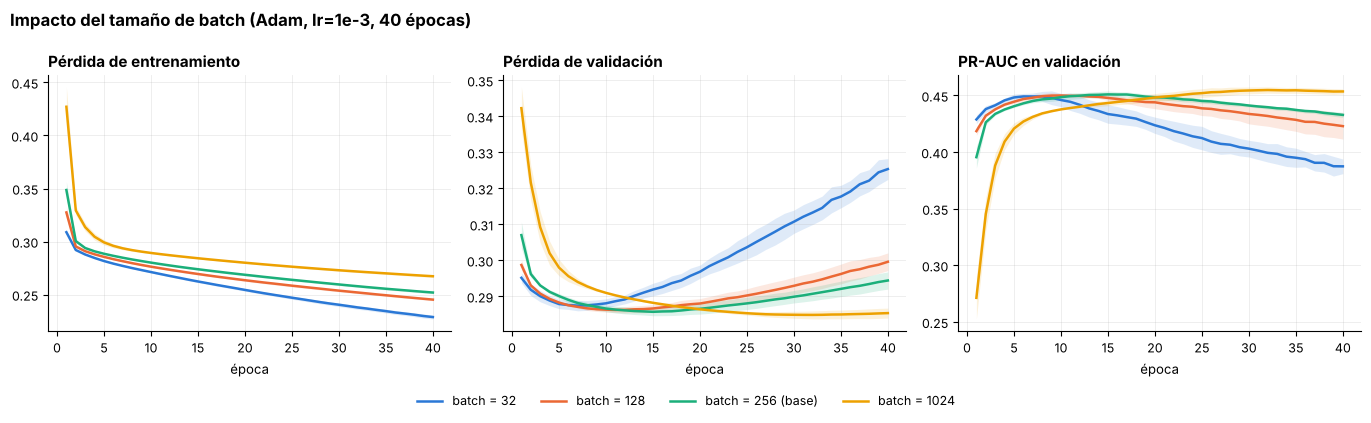

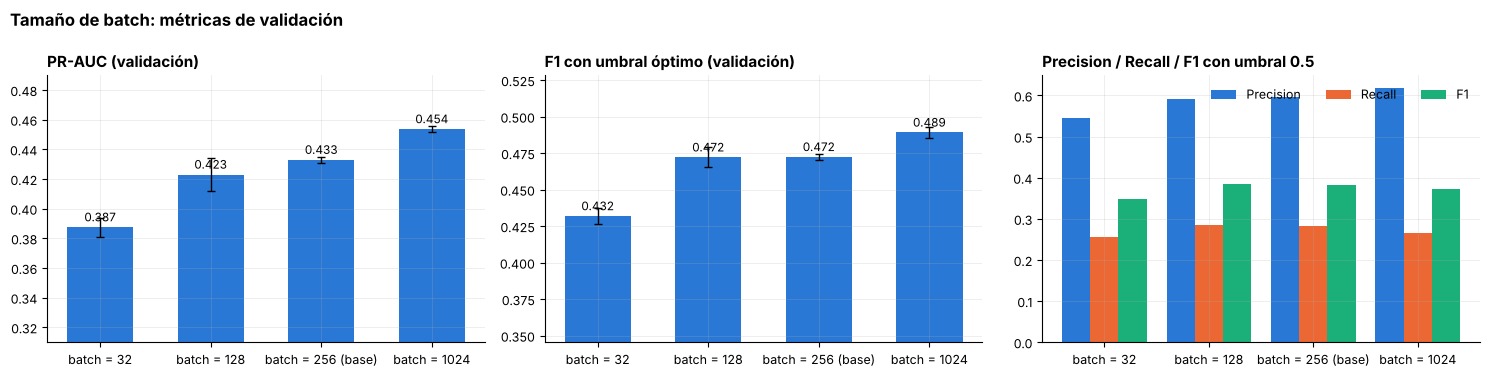

In [ ]:
print("Experimento: tamaño de batch")
r_bs = []
for bs in [32, 128, 256, 1024]:
    r_bs.append({**r_base, "nombre": "batch = 256 (base)"} if bs == 256 else correr(f"batch = {bs}", {}, batch=bs))
t_bs = tabla(r_bs, "batch")
t_bs["actualizaciones/época"] = [int(np.ceil(len(datos["ytr"]) / b)) for b in [32, 128, 256, 1024]]
display(t_bs)
grafico_curvas(r_bs, "Impacto del tamaño de batch (Adam, lr=1e-3, 40 épocas)", "param_batch")
grafico_barras(r_bs, "Tamaño de batch: métricas de validación", "param_batch_barras", rot=0)

### Análisis: tamaño de batch (Adam, lr = 1e-3, 40 épocas)

| Batch | Actualizaciones/época | PR-AUC | F1 óptimo | Pérdida val | Tiempo (s) |
|---|---|---|---|---|---|
| 32 | 989 | 0,387 | 0,432 | 0,325 | 79,9 |
| 128 | 248 | 0,423 | 0,472 | 0,300 | 24,9 |
| **256 (base)** | 124 | 0,433 | 0,472 | 0,294 | 15,0 |
| 1024 | 31 | **0,454** | **0,489** | **0,285** | **8,4** |

* **Costo computacional:** pasar de batch 32 a 1024 reduce el tiempo de entrenamiento ~10× (79,9 s → 8,4 s), porque se hacen 32× menos actualizaciones por época y se aprovecha mejor el cálculo vectorizado.
* **Rendimiento:** con épocas fijas, **a mayor batch, mejor PR-AUC** (0,387 → 0,454). De nuevo hay que leerlo con cuidado: con batch 32 se dan 989 pasos por época, 32 veces más que con 1024, así que la red **sobreajusta mucho antes** (su pérdida de validación es la peor: 0,325). El batch pequeño introduce más ruido en el gradiente, lo que *puede* regularizar, pero aquí domina el efecto de "más pasos = más sobreajuste".
* **Respaldo del material (1.4.2):** "lo que importa es la cantidad de iteraciones del descenso del gradiente y no la cantidad de épocas". Por eso, a épocas fijas, el batch 32 (989 actualizaciones por época) sobreajusta antes que el 1024 (31 actualizaciones).
* **Decisión:** batch **512** como compromiso: rápido, estable (desviación entre semillas baja) y sin el sesgo de pocas actualizaciones. La búsqueda de hiperparámetros lo confirma: 512 es el valor con mejor PR-AUC medio (0,455) y 1024 el peor (0,449).

### 4.6 Parámetro 4 — Número de capas y neuronas (arquitectura)
No existe un número "correcto" de capas: depende de los datos y del problema (material 1.2.1). Más capas/neuronas = más capacidad, pero también más riesgo de sobreajuste, más tiempo y más problemas de gradientes. Comparamos desde una red muy pequeña hasta una profunda.

Experimento: arquitectura (número de capas y neuronas)


  · 16-8                         PR-AUC=0.447  F1*=0.481  (907s acumulados)


  · 64 (1 capa)                  PR-AUC=0.454  F1*=0.487  (951s acumulados)


  · 128-64-32 (3 capas)          PR-AUC=0.356  F1*=0.406  (1,011s acumulados)


  · 256-128-64-32 (4 capas)      PR-AUC=0.318  F1*=0.361  (1,077s acumulados)


  · 256-128 (ancha)              PR-AUC=0.358  F1*=0.405  (1,135s acumulados)


,Accuracy,Precision,Recall,F1 (umbral 0.5),F1 (umbral óptimo),PR-AUC,± PR-AUC,ROC-AUC,val_loss,épocas,tiempo (s),parámetros
configuración,,,,,,,,,,,,
16-8,0.896,0.631,0.264,0.372,0.481,0.447,0.004,0.794,0.287,40.0,14.596,945
64 (1 capa),0.895,0.625,0.264,0.371,0.487,0.454,0.006,0.801,0.284,40.0,14.479,3265
64-32 (base),0.894,0.596,0.282,0.382,0.472,0.433,0.002,0.792,0.294,40.0,14.952,5313
128-64-32 (3 capas),0.877,0.475,0.309,0.371,0.406,0.356,0.019,0.737,0.394,40.0,19.332,16769
256-128-64-32 (4 capas),0.869,0.415,0.298,0.346,0.361,0.318,0.018,0.687,0.666,40.0,21.236,56065
256-128 (ancha),0.879,0.479,0.306,0.372,0.405,0.358,0.016,0.741,0.391,40.0,18.977,45825


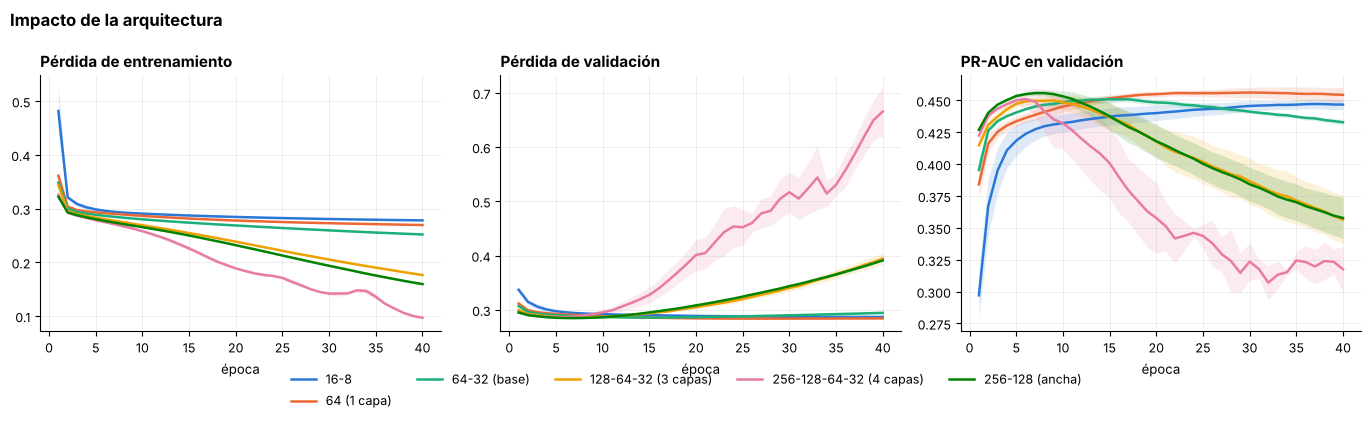

In [ ]:
print("Experimento: arquitectura (número de capas y neuronas)")
archs = {"16-8": (16, 8), "64 (1 capa)": (64,), "64-32 (base)": (64, 32), "128-64-32 (3 capas)": (128, 64, 32),
         "256-128-64-32 (4 capas)": (256, 128, 64, 32), "256-128 (ancha)": (256, 128)}
r_arq = [{**r_base, "nombre": n} if n == "64-32 (base)" else correr(n, {"capas": c}) for n, c in archs.items()]
t_arq = tabla(r_arq, "arquitectura")
t_arq["parámetros"] = [int(sum(np.prod(w) for w in [(49 if i == 0 else cc[i-1], u) for i, u in enumerate(cc)]) + sum(cc) + cc[-1] + 1) for cc in archs.values()]
display(t_arq)
grafico_curvas(r_arq, "Impacto de la arquitectura", "param_arquitectura")

### Análisis: número de capas y neuronas (40 épocas, sin regularización)

| Arquitectura | Parámetros | PR-AUC | F1 óptimo | Pérdida val |
|---|---|---|---|---|
| 16-8 | 945 | 0,447 | 0,481 | 0,287 |
| **64 (1 capa)** | 3.265 | **0,454** | **0,487** | **0,284** |
| 64-32 (base) | 5.313 | 0,433 | 0,472 | 0,294 |
| 128-64-32 | 16.769 | 0,356 | 0,406 | 0,394 |
| 256-128-64-32 | 56.065 | 0,318 | 0,361 | 0,666 |
| 256-128 | 45.825 | 0,358 | 0,405 | 0,391 |

* **Más capacidad empeora el resultado** cuando no hay regularización: a más parámetros, mayor sobreajuste (la pérdida de validación se dispara a 0,666 en la red de 4 capas) y mayor variabilidad entre semillas (0,018 vs 0,002–0,006). Las redes pequeñas (16-8 y 64) obtienen lo mismo o más con 5–60 veces menos parámetros.
* **Por qué:** el dataset es tabular, de ~32 mil filas y 49 variables con señal moderada; no hay estructura jerárquica compleja que justifique redes profundas (a diferencia de imágenes o texto). Una red grande tiene "espacio de sobra" para memorizar el ruido.
* **Pero la capacidad no es mala por sí misma:** en la sección 6.2 la red 256-128-64 con L2/Dropout o Early Stopping alcanza PR-AUC 0,448–0,455, igual o mejor que las redes pequeñas. Por eso la búsqueda de la sección 7 explora arquitecturas de 1 a 3 capas **junto con** regularización, y la ganadora es una red intermedia (**128-64**).

## 5. Funciones de activación, pérdida y salida

### 5.1 Funciones de activación (capas ocultas)
Aportan la **no linealidad**. Cuatro conceptos del material que guían la comparación:

| Función | Fórmula | Rango | Comportamiento del gradiente |
|---|---|---|---|
| **Sigmoide** | $1/(1+e^{-u})$ | (0, 1) | Se **satura** en los extremos: derivada $\le 0{,}25$ y ≈ 0 para $|u|$ grande → *desvanecimiento del gradiente* |
| **Tanh** | $\tanh(u)$ | (−1, 1) | Centrada en 0 (mejor que sigmoide) pero también se satura |
| **ReLU** | $\max(0,u)$ | [0, ∞) | Derivada 1 para $u>0$ → el gradiente no se desvanece; riesgo de "neuronas muertas" si $u<0$ siempre |
| **Leaky ReLU / ELU** | pendiente pequeña para $u<0$ | | Evitan neuronas muertas |
| **Lineal** (control) | $u$ | ℝ | Sin no linealidad: la red completa equivale a una regresión logística |

Mantenemos **todo igual** (arquitectura 64-32, BCE, Adam, lr, batch) y cambiamos **solo la activación oculta**.

Experimento: funciones de activación (capas ocultas)


  · Leaky ReLU                   PR-AUC=0.441  F1*=0.485  (1,183s acumulados)


  · ELU                          PR-AUC=0.449  F1*=0.491  (1,230s acumulados)


  · Tanh                         PR-AUC=0.440  F1*=0.479  (1,278s acumulados)


  · Sigmoide                     PR-AUC=0.425  F1*=0.462  (1,327s acumulados)


  · Lineal (control)             PR-AUC=0.418  F1*=0.454  (1,373s acumulados)


,Accuracy,Precision,Recall,F1 (umbral 0.5),F1 (umbral óptimo),PR-AUC,± PR-AUC,ROC-AUC,val_loss,épocas,tiempo (s)
configuración,,,,,,,,,,,
ReLU (base),0.894,0.596,0.282,0.382,0.472,0.433,0.002,0.792,0.294,40.0,14.952
Leaky ReLU,0.895,0.617,0.272,0.377,0.485,0.441,0.006,0.796,0.289,40.0,15.180
ELU,0.895,0.625,0.261,0.368,0.491,0.449,0.003,0.803,0.284,40.0,14.957
Tanh,0.894,0.614,0.263,0.368,0.479,0.440,0.001,0.797,0.287,40.0,15.393
Sigmoide,0.892,0.610,0.217,0.320,0.462,0.425,0.002,0.780,0.294,40.0,15.627
Lineal (control),0.892,0.632,0.181,0.281,0.454,0.418,0.001,0.772,0.299,40.0,14.817


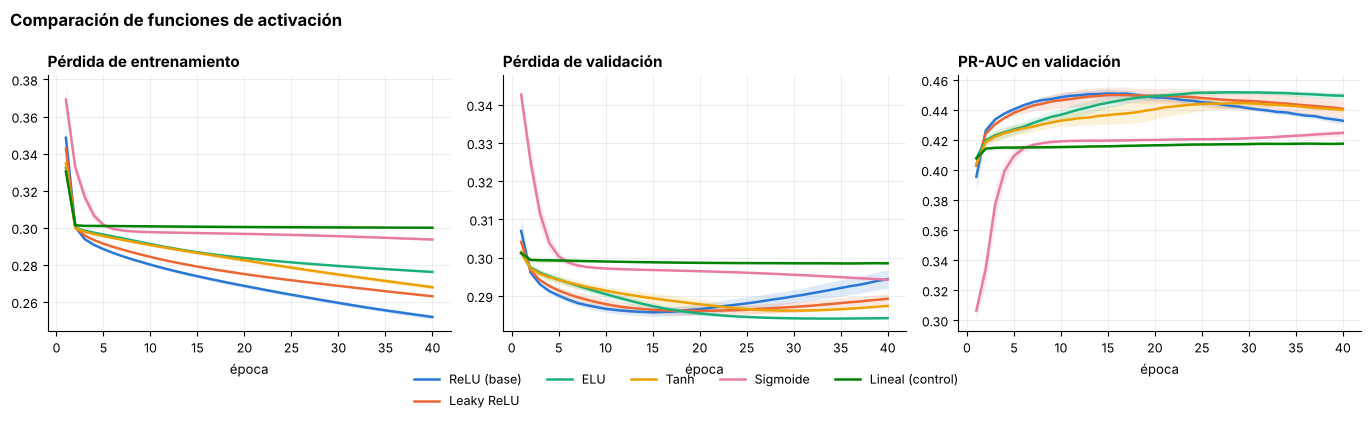

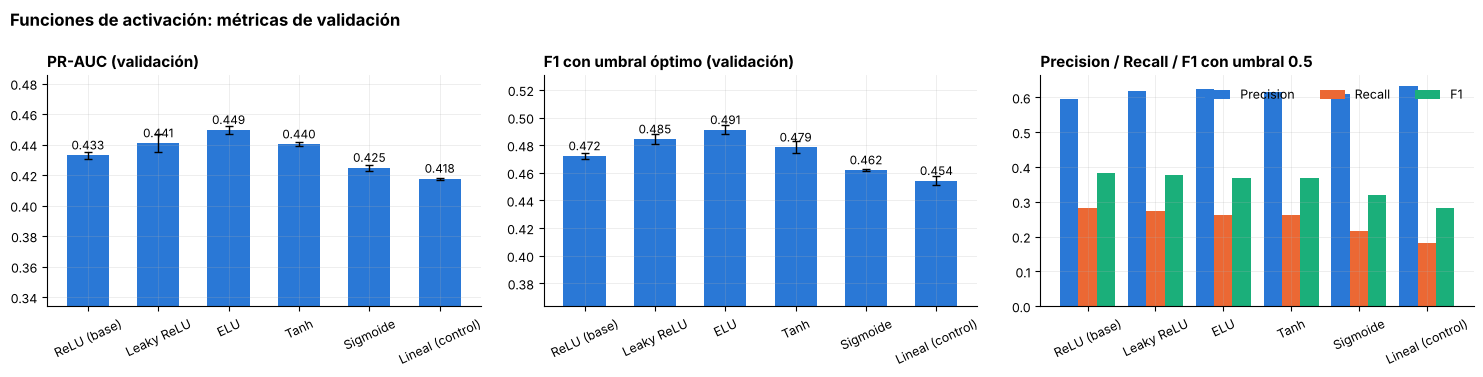

In [ ]:
print("Experimento: funciones de activación (capas ocultas)")
acts = {"ReLU (base)": "relu", "Leaky ReLU": "leaky_relu", "ELU": "elu", "Tanh": "tanh", "Sigmoide": "sigmoid", "Lineal (control)": "linear"}
r_act = [{**r_base, "nombre": n} if a == "relu" else correr(n, {"activacion": a}) for n, a in acts.items()]
display(tabla(r_act, "activacion"))
grafico_curvas(r_act, "Comparación de funciones de activación", "act_curvas")
grafico_barras(r_act, "Funciones de activación: métricas de validación", "act_barras", rot=25)

### Análisis: funciones de activación (red base, 40 épocas)

| Activación | PR-AUC | ± | F1 óptimo | Recall (0.5) | Pérdida val |
|---|---|---|---|---|---|
| ELU | **0,449** | 0,003 | **0,491** | 0,261 | 0,284 |
| Leaky ReLU | 0,441 | 0,006 | 0,485 | 0,272 | 0,289 |
| Tanh | 0,440 | 0,001 | 0,479 | 0,263 | 0,287 |
| ReLU (base) | 0,433 | 0,002 | 0,472 | 0,282 | 0,294 |
| Sigmoide | 0,425 | 0,002 | 0,462 | 0,217 | 0,294 |
| Lineal (control) | 0,418 | 0,001 | 0,454 | 0,181 | 0,299 |

* **Orden general:** las activaciones tipo ReLU (ELU, Leaky ReLU, ReLU) y tanh quedan agrupadas (0,433–0,449), la sigmoide un poco por debajo (0,425) y la **lineal** al final (0,418). La diferencia entre la mejor y la peor es de solo ~0,03 de PR-AUC: en una red de **2 capas** el efecto de la activación es pequeño.
* **El control lineal es muy informativo:** sin no linealidad la red equivale a una regresión logística y logra 0,418. Que las no lineales solo superen eso por ~0,015–0,03 indica que **este problema es "casi lineal"**: gran parte de la señal se captura con efectos aditivos, y el aporte de la red profunda será modesto (lo confirmaremos en la evaluación contra la regresión logística).
* **Sigmoide y tanh** muestran su problema de saturación (gradiente ≈ 0 en los extremos, material 1.2.1); con solo 2 capas se nota poco, pero la siguiente demostración muestra qué pasa cuando hay muchas capas.
* **Cautela:** estas diferencias se midieron a épocas fijas (ver 4.3); por eso en la sección 7.2 se **confirma** la elección con la configuración final y Early Stopping.

### 5.2 ¿Por qué se satura la sigmoide? Demostración con el gradiente
En un dataset pequeño con 2 capas la diferencia es sutil. El problema real aparece con **muchas capas**: por la regla de la cadena, el gradiente de la primera capa es un **producto** de derivadas de cada capa; si cada derivada es < 1 (sigmoide ≤ 0,25), el producto se encoge exponencialmente (*desvanecimiento del gradiente*, material 1.6.1).

Lo comprobamos de forma directa: construimos una red de **12 capas ocultas** (32 neuronas) y medimos la **norma del gradiente** de cada capa en una pasada de *backpropagation* con un mismo batch. Luego entrenamos esas redes profundas con descenso del gradiente simple (SGD) para ver el efecto en el aprendizaje.

  · Sigmoide (12 capas)          PR-AUC=0.116  F1*=0.209  (1,391s acumulados)


  · ReLU + He (12 capas)         PR-AUC=0.411  F1*=0.450  (1,405s acumulados)


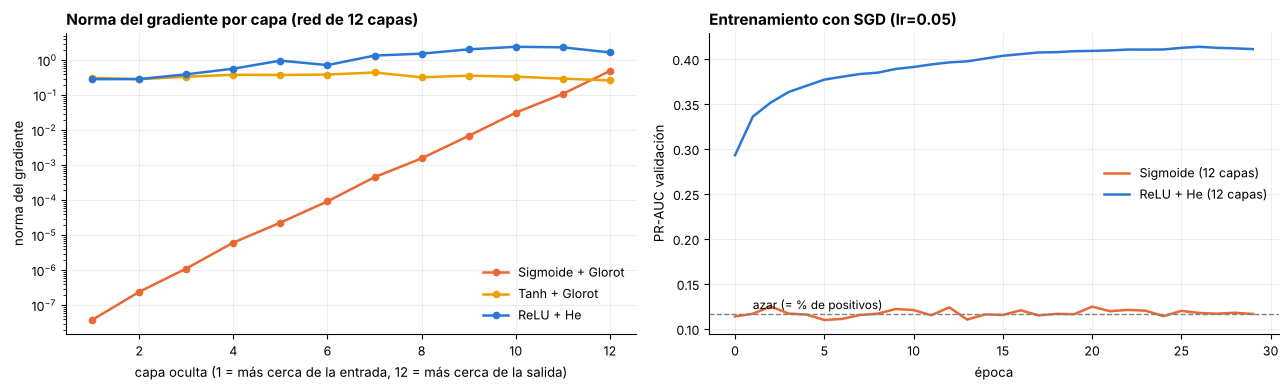

Razón gradiente(capa 12) / gradiente(capa 1): {'Sigmoide + Glorot': 12916342.1, 'Tanh + Glorot': 0.8, 'ReLU + He': 5.8}


In [ ]:
def normas_gradiente(activacion, n_capas=12, ancho=32, seed=0, init="glorot_uniform"):
    keras.utils.set_random_seed(seed)
    m = construir_mlp(datos["Xtr"].shape[1], capas=(ancho,) * n_capas, activacion=activacion, init=init)
    xb = tf.constant(datos["Xtr"][:4096]); yb = tf.constant(datos["ytr"][:4096].astype("float32")[:, None])
    with tf.GradientTape() as tape:
        perdida = tf.reduce_mean(keras.losses.binary_crossentropy(yb, m(xb)))
    grads = tape.gradient(perdida, m.trainable_variables)
    out = [float(tf.norm(g)) for v, g in zip(m.trainable_variables, grads) if v.name == "kernel"]
    keras.backend.clear_session()
    return out[:-1]          # solo capas ocultas (excluye la capa de salida)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
normas = {}
for i, (n, a, ini) in enumerate([("Sigmoide + Glorot", "sigmoid", "glorot_uniform"), ("Tanh + Glorot", "tanh", "glorot_uniform"),
                                  ("ReLU + He", "relu", "he_normal")]):
    normas[n] = normas_gradiente(a, init=ini)
    axs[0].plot(range(1, 13), normas[n], marker="o", ms=4.5, color=COLORES[[1, 3, 0][i]], label=n)
axs[0].set_yscale("log"); axs[0].set_xlabel("capa oculta (1 = más cerca de la entrada, 12 = más cerca de la salida)")
axs[0].set_ylabel("norma del gradiente"); axs[0].set_title("Norma del gradiente por capa (red de 12 capas)"); axs[0].legend()

# Entrenamiento de la red profunda con SGD simple
res_prof = []
for n, a, ini in [("Sigmoide (12 capas)", "sigmoid", "glorot_uniform"), ("ReLU + He (12 capas)", "relu", "he_normal")]:
    res_prof.append(correr(n, {"capas": (32,) * 12, "activacion": a, "init": ini, "optimizador": "sgd", "lr": 0.05}, seeds=[SEED], epochs=30))
for i, r in enumerate(res_prof):
    axs[1].plot(r["hist"][0]["val_pr_auc"], color=COLORES[[1, 0][i]], label=r["nombre"])
axs[1].axhline(datos["yva"].mean(), color="gray", ls="--", lw=1); axs[1].text(1, datos["yva"].mean() + 0.005, "azar (= % de positivos)", fontsize=8.5)
axs[1].set_xlabel("época"); axs[1].set_ylabel("PR-AUC validación"); axs[1].set_title("Entrenamiento con SGD (lr=0.05)"); axs[1].legend()
plt.tight_layout(); guardar("act_gradientes"); plt.show()

raz = {n: v[-1] / v[0] for n, v in normas.items()}
print("Razón gradiente(capa 12) / gradiente(capa 1):", {n: round(r, 1) for n, r in raz.items()})
RESULTADOS["gradientes"] = {"normas": normas, "razon_ultima_primera": raz,
                            "pr_auc_final": {r["nombre"]: float(r["filas"].pr_auc.iloc[0]) for r in res_prof}}

### Análisis: desvanecimiento del gradiente (red de 12 capas)

* **Medición directa (izquierda).** Con sigmoide, la norma del gradiente en la capa más cercana a la salida es ~0,5, pero en la primera capa es ~4·10⁻⁸: **13 millones de veces menor** (razón última/primera = 1,3·10⁷). Cada capa multiplica el gradiente por una derivada de la sigmoide (≤ 0,25), y el producto de 12 factores pequeños se desvanece exponencialmente: las capas iniciales casi no reciben señal para aprender. Con ReLU + He el gradiente se mantiene en el mismo orden de magnitud en todas las capas (razón 5,8) y con tanh + Glorot también (razón 0,8): Glorot está diseñado precisamente para mantener estable la varianza con tanh.
* **Efecto en el aprendizaje (derecha).** Entrenada con SGD, la red profunda con sigmoide **no aprende nada**: su PR-AUC queda en 0,116, igual al azar (la proporción de positivos, 0,117). La misma red con ReLU + He alcanza PR-AUC 0,411.
* **Matiz importante:** el problema es específico de la **sigmoide** (derivada máxima 0,25, salidas siempre positivas), no de "toda función saturable": tanh con inicialización Glorot se comportó bien en esta medición.
* **Conclusión para el diseño:** ReLU (y variantes) con inicialización He es la combinación segura al profundizar; es la razón técnica por la que se usa ReLU en las capas ocultas del modelo final, y por la que la sigmoide se reserva para la **capa de salida** (donde sí queremos una probabilidad en (0, 1) y no hay efecto de cadena).

### 5.3 Funciones de pérdida y de salida
La **función de pérdida** define *qué significa equivocarse*; la **función de salida** convierte la última capa en una predicción interpretable (no confundir con las activaciones ocultas; material 1.2.1). Para clasificación binaria con desbalance:

| Variante | Salida | Pérdida | Idea |
|---|---|---|---|
| **BCE (base)** | 1 neurona sigmoide | Entropía cruzada binaria | Estándar probabilístico; gradiente grande cuando se equivoca con seguridad |
| **MSE** | 1 neurona sigmoide | Error cuadrático medio | Pensada para regresión; con sigmoide su gradiente se atenúa cuando la salida satura (aprende más lento) |
| **BCE con pesos de clase** | sigmoide | BCE ponderada (clase "yes" pesa ≈ 7,5×) | Hace que equivocarse en un positivo cueste más → sube el *recall* |
| **Focal loss** | sigmoide | BCE modulada $(1-p_t)^{\gamma}$ con $\gamma=2$, $\alpha=0{,}75$ | Reduce el peso de los ejemplos "fáciles" (la mayoría "no") y se concentra en los difíciles |
| **Softmax (2 neuronas)** | softmax | Entropía cruzada categórica | Equivalente matemático a la sigmoide en 2 clases, con el doble de parámetros en la salida |

> Ojo: con pesos de clase o *focal loss* las salidas dejan de ser probabilidades calibradas, por lo que el umbral 0,5 deja de ser óptimo. Por eso se reportan **PR-AUC** (independiente del umbral) y **F1 con umbral óptimo** además de las métricas a 0,5.

Experimento: funciones de pérdida y de salida


  · MSE + sigmoide               PR-AUC=0.423  F1*=0.467  (1,454s acumulados)


  · BCE con pesos de clase       PR-AUC=0.433  F1*=0.470  (1,502s acumulados)


  · Focal loss (γ=2, α=0.75)     PR-AUC=0.415  F1*=0.461  (1,551s acumulados)


  · Softmax (2 salidas) + CE     PR-AUC=0.421  F1*=0.465  (1,600s acumulados)


,Accuracy,Precision,Recall,F1 (umbral 0.5),F1 (umbral óptimo),PR-AUC,± PR-AUC,ROC-AUC,val_loss,épocas,tiempo (s)
configuración,,,,,,,,,,,
BCE + sigmoide (base),0.894,0.596,0.282,0.382,0.472,0.433,0.002,0.792,0.294,40.0,14.952
MSE + sigmoide,0.892,0.580,0.287,0.382,0.467,0.423,0.005,0.783,0.085,40.0,15.425
BCE con pesos de clase,0.786,0.307,0.650,0.416,0.470,0.433,0.006,0.791,0.504,40.0,15.390
"Focal loss (γ=2, α=0.75)",0.870,0.448,0.470,0.458,0.461,0.415,0.014,0.777,0.041,40.0,15.673
Softmax (2 salidas) + CE,0.892,0.577,0.278,0.375,0.465,0.421,0.009,0.784,0.300,40.0,15.453


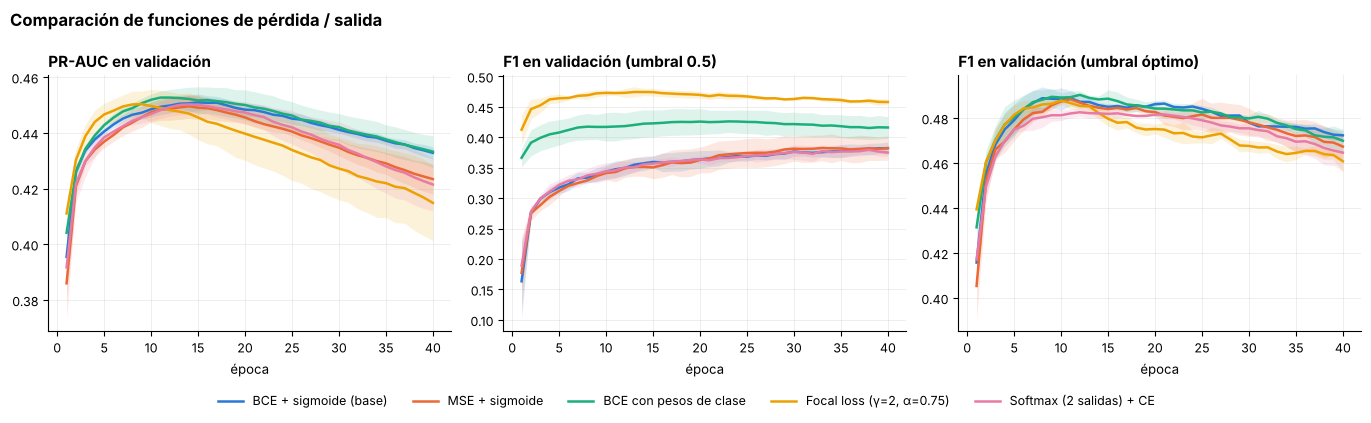

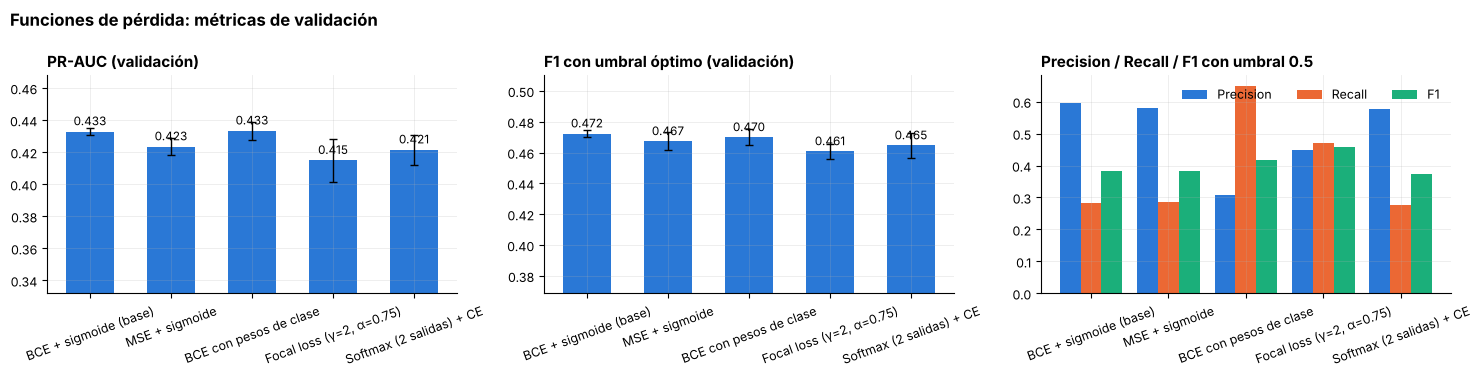

In [ ]:
print("Experimento: funciones de pérdida y de salida")
r_loss = [
    {**r_base, "nombre": "BCE + sigmoide (base)"},
    correr("MSE + sigmoide", {"perdida": "mse"}),
    correr("BCE con pesos de clase", {}, pesos=True),
    correr("Focal loss (γ=2, α=0.75)", {"perdida": "focal"}),
    correr("Softmax (2 salidas) + CE", {"salida": "softmax", "perdida": "sparse_categorical_crossentropy"}),
]
display(tabla(r_loss, "perdida"))
grafico_curvas(r_loss, "Comparación de funciones de pérdida / salida", "loss_curvas",
               paneles=(("val_pr_auc", "PR-AUC en validación"), ("val_f1_05", "F1 en validación (umbral 0.5)"), ("val_f1_max", "F1 en validación (umbral óptimo)")))
grafico_barras(r_loss, "Funciones de pérdida: métricas de validación", "loss_barras", rot=20)

### Análisis: funciones de pérdida y de salida (red base, 40 épocas)

| Variante | PR-AUC | F1 óptimo | Precision (0.5) | Recall (0.5) | F1 (0.5) | Accuracy (0.5) |
|---|---|---|---|---|---|---|
| **BCE + sigmoide (base)** | **0,433** | **0,472** | 0,596 | 0,282 | 0,382 | 0,894 |
| MSE + sigmoide | 0,423 | 0,467 | 0,580 | 0,287 | 0,382 | 0,892 |
| BCE con pesos de clase | **0,433** | 0,470 | 0,307 | 0,650 | 0,416 | 0,786 |
| Focal loss (γ=2, α=0,75) | 0,415 | 0,461 | 0,448 | 0,470 | 0,458 | 0,870 |
| Softmax (2 salidas) + CE | 0,421 | 0,465 | 0,577 | 0,278 | 0,375 | 0,892 |

* **La pérdida casi no cambia la calidad del *ranking*.** El PR-AUC (independiente del umbral) está entre 0,415 y 0,433 y el F1 con umbral óptimo entre 0,461 y 0,472: todas las variantes ordenan a los clientes de forma parecida.
* **Lo que sí cambia es el punto de operación (umbral 0,5).** BCE estándar es "conservador" (Precision 0,596, Recall 0,282). Con **pesos de clase** el costo de equivocarse en un "yes" sube ~7,5×, y la red sube el Recall a 0,650 a costa de la Precision (0,307) y de la Accuracy (0,786, por debajo del 88 % del modelo trivial: ¡y aun así es mejor modelo!). La **focal loss** logra el mejor equilibrio *al umbral 0,5* (P 0,448 / R 0,470 / F1 0,458), aunque su PR-AUC es algo menor (0,415) y más variable (± 0,014).
* **Comparabilidad:** los valores de "pérdida de validación" de MSE (0,085) o focal (0,041) **no son comparables** con BCE (0,294), porque son funciones distintas; por eso se compara con métricas.
* **MSE vs BCE:** MSE queda ligeramente por debajo (0,423): con salida sigmoide su gradiente se atenúa cuando la neurona satura aunque la predicción sea muy mala, mientras la BCE mantiene gradientes grandes cuando la red "se equivoca con seguridad". **Softmax vs sigmoide:** son matemáticamente equivalentes en 2 clases y aquí la diferencia es pequeña (0,421 vs 0,433) mientras softmax duplica los parámetros de salida.
* **Decisión para el modelo final:** **sigmoide + entropía cruzada binaria con pesos de clase**. Razones: (i) BCE es la pérdida natural para una probabilidad Bernoulli; (ii) los pesos de clase igualan el PR-AUC de BCE (0,433) pero entrenan a la red para "prestar atención" a la clase minoritaria; (iii) como el umbral final se **elige en validación**, no dependemos de que 0,5 sea un buen corte. La búsqueda de hiperparámetros confirma que los pesos ayudan levemente (PR-AUC medio 0,4557 con pesos vs 0,4515 sin ellos).

## 6. Optimización y regularización

### 6.1 Optimizadores
Un **optimizador** decide cómo actualizar los pesos con el gradiente. Comparamos la familia vista en clases (material 1.6.1), cada uno con una tasa de aprendizaje habitual:

* **SGD**: paso fijo $\lambda$; **SGD + Momentum**: acumula la dirección de gradientes pasados (amortigua zigzags); **Nesterov**: evalúa el gradiente *antes* de dar el salto.
* **AdaGrad**: tasa distinta por parámetro (acumula cuadrados de gradientes; la tasa solo decrece).
* **RMSProp**: como AdaGrad pero con promedio móvil exponencial (olvida el pasado lejano).
* **Adam**: según el material, "combina lo mejor de AdaGrad y RMSProp" (1.6.1) o "de SGD con momentum y AdaGrad" (1.6.2). Técnicamente, su 1.er momento (media de los gradientes) actúa como Momentum y su 2.º momento (varianza) escala la tasa por parámetro como RMSProp.

Experimento: optimizadores


  · SGD (lr=0.01)                PR-AUC=0.404  F1*=0.427  (1,646s acumulados)


  · SGD (lr=0.1)                 PR-AUC=0.452  F1*=0.487  (1,691s acumulados)


  · SGD + Momentum (0.01)        PR-AUC=0.450  F1*=0.485  (1,738s acumulados)


  · SGD + Nesterov (0.01)        PR-AUC=0.450  F1*=0.487  (1,786s acumulados)


  · AdaGrad (0.01)               PR-AUC=0.431  F1*=0.464  (1,830s acumulados)


  · RMSProp (0.001)              PR-AUC=0.439  F1*=0.478  (1,878s acumulados)


,Accuracy,Precision,Recall,F1 (umbral 0.5),F1 (umbral óptimo),PR-AUC,± PR-AUC,ROC-AUC,val_loss,épocas,tiempo (s)
configuración,,,,,,,,,,,
SGD (lr=0.01),0.893,0.686,0.149,0.245,0.427,0.404,0.002,0.770,0.302,40.0,14.297
SGD (lr=0.1),0.895,0.646,0.227,0.336,0.487,0.452,0.005,0.796,0.287,40.0,14.040
SGD + Momentum (0.01),0.895,0.630,0.238,0.346,0.485,0.450,0.007,0.797,0.286,40.0,14.995
SGD + Nesterov (0.01),0.894,0.629,0.236,0.343,0.487,0.450,0.007,0.796,0.286,40.0,15.258
AdaGrad (0.01),0.893,0.641,0.190,0.293,0.464,0.431,0.001,0.786,0.293,40.0,14.172
RMSProp (0.001),0.895,0.616,0.268,0.373,0.478,0.439,0.003,0.797,0.291,40.0,15.147
Adam (0.001) (base),0.894,0.596,0.282,0.382,0.472,0.433,0.002,0.792,0.294,40.0,14.952


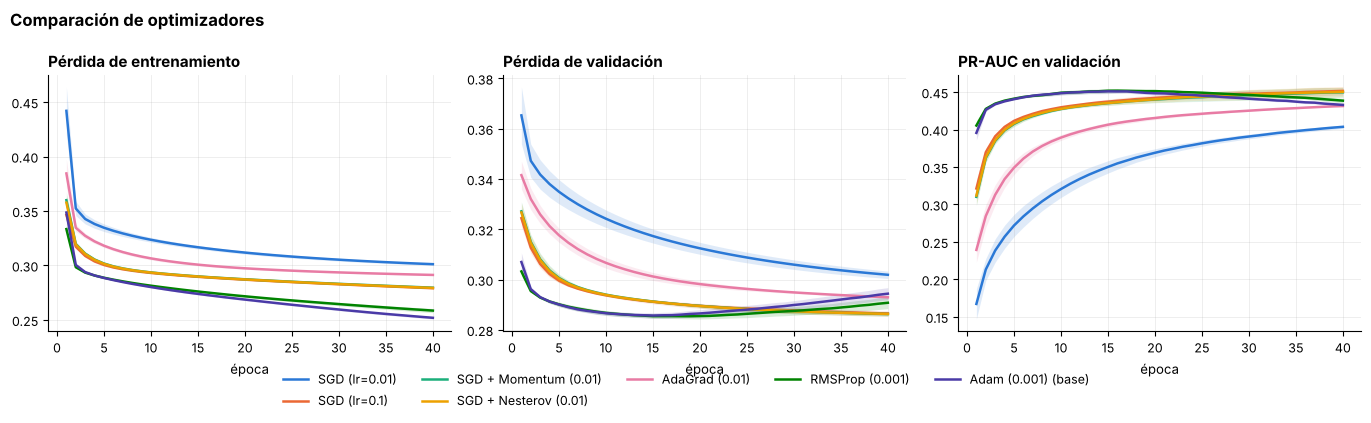

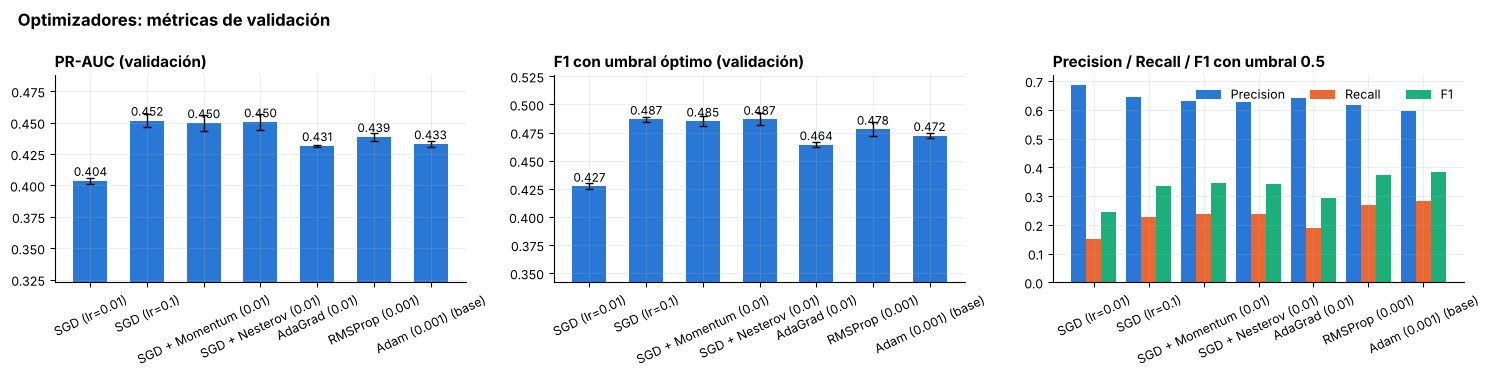

In [ ]:
print("Experimento: optimizadores")
r_opt = [
    correr("SGD (lr=0.01)", {"optimizador": "sgd", "lr": 0.01}),
    correr("SGD (lr=0.1)", {"optimizador": "sgd", "lr": 0.1}),
    correr("SGD + Momentum (0.01)", {"optimizador": "sgd_momentum", "lr": 0.01}),
    correr("SGD + Nesterov (0.01)", {"optimizador": "sgd_nesterov", "lr": 0.01}),
    correr("AdaGrad (0.01)", {"optimizador": "adagrad", "lr": 0.01}),
    correr("RMSProp (0.001)", {"optimizador": "rmsprop", "lr": 1e-3}),
    {**r_base, "nombre": "Adam (0.001) (base)"},
]
display(tabla(r_opt, "optimizadores"))
grafico_curvas(r_opt, "Comparación de optimizadores", "opt_curvas")
grafico_barras(r_opt, "Optimizadores: métricas de validación", "opt_barras", rot=25)

### Análisis: optimizadores (red base, 40 épocas)

| Optimizador | PR-AUC | F1 óptimo | Recall (0.5) | Pérdida val |
|---|---|---|---|---|
| SGD (lr 0,01) | 0,404 | 0,427 | 0,149 | 0,302 |
| SGD (lr 0,1) | **0,452** | 0,487 | 0,227 | 0,287 |
| SGD + Momentum (0,01) | 0,450 | 0,485 | 0,238 | 0,286 |
| SGD + Nesterov (0,01) | 0,450 | **0,487** | 0,236 | 0,286 |
| AdaGrad (0,01) | 0,431 | 0,464 | 0,190 | 0,293 |
| RMSProp (0,001) | 0,439 | 0,478 | 0,268 | 0,291 |
| **Adam (0,001) (base)** | 0,433 | 0,472 | 0,282 | 0,294 |

* **SGD simple con lr = 0,01 es el peor** (PR-AUC 0,404, Recall 0,149): el paso fijo y pequeño hace que a las 40 épocas la red aún esté *subajustada*. **Momentum y Nesterov** (misma lr 0,01) suben a 0,450 porque acumulan la dirección de los gradientes y avanzan más rápido; Nesterov y Momentum son prácticamente iguales. Con lr = 0,1, SGD simple también llega a 0,452: es el mismo efecto (el parámetro `lr` de SGD es crítico y hay que "tunearlo", justo lo que automatizan los optimizadores adaptativos).
* **Los adaptativos** (AdaGrad 0,431, RMSProp 0,439, Adam 0,433) funcionan **sin ajustar la tasa de aprendizaje** y quedan en el mismo rango. AdaGrad es algo más lento, coherente con que su tasa de aprendizaje solo decrece al acumular cuadrados de gradientes.
* **Lectura honesta:** con 40 épocas fijas, SGD+Momentum/Nesterov parecen "ganar" por ~0,02 de PR-AUC, pero recordemos que Adam ya está sobreajustando a las 40 épocas (óptimo ≈ 15). Con Early Stopping los optimizadores convergen a niveles parecidos; la diferencia relevante es **cuánto cuesta llegar** y **cuánto sensibilizan al `lr`**.
* **Decisión:** **Adam (lr = 1e-3)**: converge en pocas épocas, es robusto a la elección de `lr` (justo en la sección 4.4 vimos que con 1e-4 y 1e-3 el comportamiento es estable) y adapta la tasa de aprendizaje por parámetro (material 1.6.1 y 1.6.2). Es una elección de **robustez y velocidad**, no de un rendimiento superior demostrado. El material 1.6.1 respalda esta lectura: "no hay suficiente evidencia para declarar uno mejor que otro" y "para experimentos rápidos, Adam es una buena elección"; con tiempo se podría repetir esta comparación con Early Stopping.

### 6.2 Regularización: ¿cómo evitar el sobreajuste?
La regularización busca **reducir la brecha entre el error de entrenamiento y el de generalización** haciendo al modelo más "simple" (material 1.5.1). Para que el efecto sea visible usamos una red **más grande (256-128-64)**, que tiene capacidad de sobra para memorizar, y la entrenamos 60 épocas. Técnicas probadas:

| Técnica | Qué hace |
|---|---|
| **Regularización L2** (*weight decay*) | Suma $\lambda_2\sum w^2$ a la pérdida: penaliza pesos grandes y suaviza la función |
| **Dropout** (p = 0,3) | Apaga neuronas al azar en cada batch (solo en entrenamiento): obliga a la red a no depender de neuronas concretas |
| **Batch Normalization** | Normaliza las activaciones de cada capa por mini-lote (media 0, varianza 1) + parámetros $\gamma,\beta$ entrenables; estabiliza y regulariza |
| **Early Stopping** | Detiene el entrenamiento cuando la pérdida de validación deja de mejorar (paciencia = 5 épocas) y restaura los mejores pesos |
| **Data augmentation** | *No aplica*: es una técnica para imágenes/audio; en datos tabulares, "inventar" filas con rotaciones o recortes no tiene sentido físico |
| **Transfer learning** | *No aplica*: no existen modelos preentrenados para estas 49 variables tabulares de un banco; es una técnica para imágenes o texto, donde sí hay redes entrenadas con millones de ejemplos |

**Medidas de estabilidad** (para los gráficos "con y sin"): mejor época y pérdida mínima de validación; **degradación** = pérdida final − pérdida mínima (cuánto empeora por sobreentrenar); **oscilación** = desviación estándar de los cambios época a época de la pérdida de validación en las últimas 20 épocas; y la desviación entre semillas del PR-AUC.

Experimento: regularización (red 256-128-64, 60 épocas)


  · Sin regularización           PR-AUC=0.294  F1*=0.343  (1,975s acumulados)


  · L2 (1e-4)                    PR-AUC=0.316  F1*=0.381  (2,075s acumulados)


  · L2 (1e-3)                    PR-AUC=0.448  F1*=0.485  (2,173s acumulados)


  · Dropout (0.3)                PR-AUC=0.394  F1*=0.442  (2,301s acumulados)


...

  · L2 + Dropout + BatchNorm     PR-AUC=0.442  F1*=0.477  (2,774s acumulados)


  · Sin reg. + Early Stopping    PR-AUC=0.455  F1*=0.488  (2,795s acumulados)


,Accuracy,Precision,Recall,F1 (umbral 0.5),F1 (umbral óptimo),PR-AUC,± PR-AUC,ROC-AUC,val_loss,épocas,tiempo (s),degradación
configuración,,,,,,,,,,,,
Sin regularización,0.871,0.422,0.261,0.319,0.343,0.294,0.005,0.680,0.912,60.000,31.124,0.6273
L2 (1e-4),0.847,0.365,0.371,0.360,0.381,0.316,0.011,0.720,0.596,60.000,32.581,0.2959
L2 (1e-3),0.896,0.619,0.288,0.393,0.485,0.448,0.006,0.798,0.298,60.000,31.667,0.0023
Dropout (0.3),0.885,0.513,0.327,0.399,0.442,0.394,0.007,0.766,0.325,60.000,41.786,0.0411
BatchNorm,0.858,0.370,0.296,0.327,0.351,0.304,0.013,0.706,0.889,60.000,43.875,0.5984
Dropout + BatchNorm,0.893,0.576,0.315,0.407,0.477,0.441,0.007,0.788,0.295,60.000,55.866,0.0118
L2 + Dropout + BatchNorm,0.893,0.584,0.306,0.401,0.477,0.442,0.003,0.787,0.312,60.000,54.925,0.0126
Sin reg. + Early Stopping,0.896,0.633,0.265,0.373,0.488,0.455,0.000,0.799,0.292,10.333,5.893,0.0070


Medidas de estabilidad:


,mejor época,val_loss mín.,val_loss final,degradación,oscilación,desv. PR-AUC (semillas)
Sin regularización,5.3333,0.2851,0.9124,0.6273,0.0320,0.0053
L2 (1e-4),7.6667,0.3005,0.5964,0.2959,0.0161,0.0106
L2 (1e-3),28.6667,0.2962,0.2984,0.0023,0.0001,0.0056
Dropout (0.3),12.6667,0.2843,0.3254,0.0411,0.0026,0.0073
BatchNorm,3.3333,0.2909,0.8893,0.5984,0.0154,0.0132
Dropout + BatchNorm,18.3333,0.2836,0.2954,0.0118,0.0010,0.0072
L2 + Dropout + BatchNorm,30.3333,0.2998,0.3124,0.0126,0.0015,0.0031
Sin reg. + Early Stopping,5.3333,0.2851,0.2921,0.0070,0.0021,0.0003


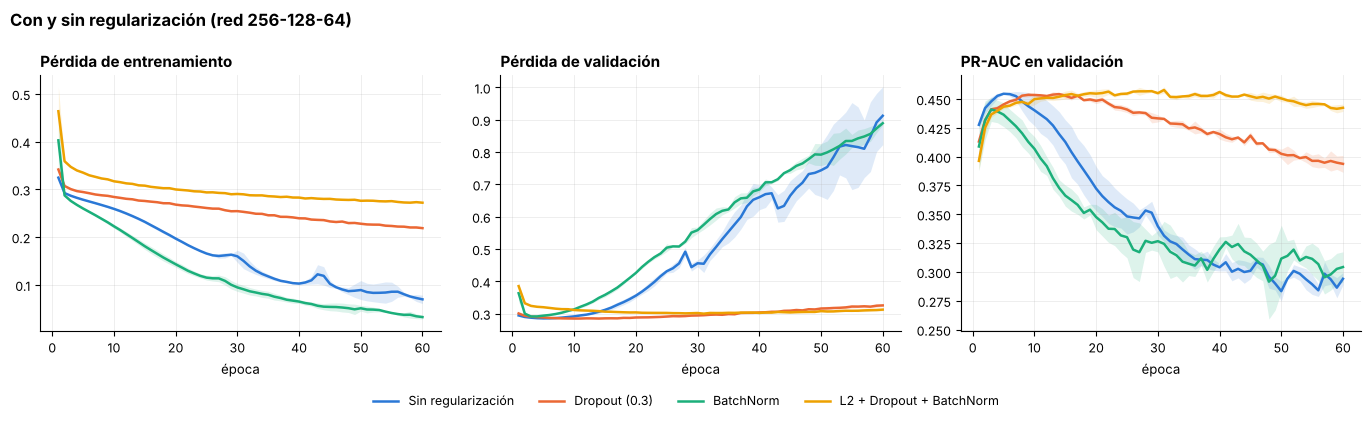

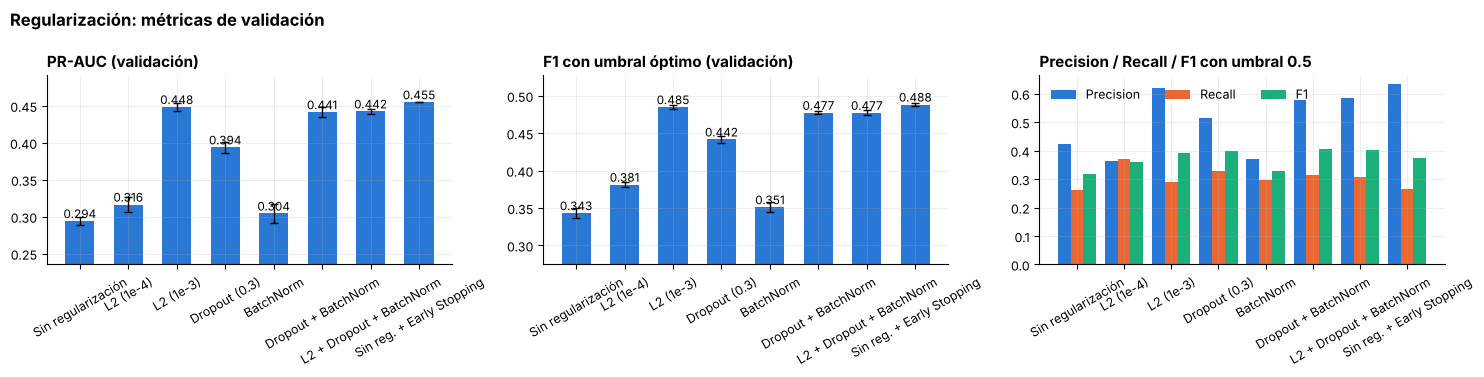

In [ ]:
print("Experimento: regularización (red 256-128-64, 60 épocas)")
GRANDE = (256, 128, 64)
EP_REG = 60
r_reg = [
    correr("Sin regularización", {"capas": GRANDE}, epochs=EP_REG),
    correr("L2 (1e-4)", {"capas": GRANDE, "l2": 1e-4}, epochs=EP_REG),
    correr("L2 (1e-3)", {"capas": GRANDE, "l2": 1e-3}, epochs=EP_REG),
    correr("Dropout (0.3)", {"capas": GRANDE, "dropout": 0.3}, epochs=EP_REG),
    correr("BatchNorm", {"capas": GRANDE, "batchnorm": True}, epochs=EP_REG),
    correr("Dropout + BatchNorm", {"capas": GRANDE, "dropout": 0.3, "batchnorm": True}, epochs=EP_REG),
    correr("L2 + Dropout + BatchNorm", {"capas": GRANDE, "l2": 1e-4, "dropout": 0.3, "batchnorm": True}, epochs=EP_REG),
    correr("Sin reg. + Early Stopping", {"capas": GRANDE}, epochs=EP_REG, monitor="val_loss", paciencia=5),
]
t_reg = tabla(r_reg)

# --- medidas de estabilidad ---
def estabilidad(r):
    filas = []
    for h in r["hist"]:
        v = np.array(h["val_loss"])
        filas.append({"mejor_epoca": int(np.argmin(v)) + 1, "val_loss_min": v.min(), "val_loss_final": v[-1],
                      "degradacion": v[-1] - v.min(), "oscilacion": np.std(np.diff(v[-20:]))})
    f = pd.DataFrame(filas)
    return {"mejor época": f.mejor_epoca.mean(), "val_loss mín.": f.val_loss_min.mean(), "val_loss final": f.val_loss_final.mean(),
            "degradación": f.degradacion.mean(), "oscilación": f.oscilacion.mean(), "desv. PR-AUC (semillas)": r["filas"].pr_auc.std(ddof=0)}
t_est = pd.DataFrame({r["nombre"]: estabilidad(r) for r in r_reg}).T.round(4)
t_reg["degradación"] = t_est["degradación"].values
display(t_reg)
print("Medidas de estabilidad:")
display(t_est)
RESULTADOS["regularizacion"] = json.loads(pd.concat([t_reg, t_est.drop(columns=["degradación"])], axis=1).round(4).to_json(orient="index"))
grafico_curvas([r_reg[0], r_reg[3], r_reg[4], r_reg[6]], "Con y sin regularización (red 256-128-64)", "reg_curvas",
               paneles=(("loss", "Pérdida de entrenamiento"), ("val_loss", "Pérdida de validación"), ("val_pr_auc", "PR-AUC en validación")))
grafico_barras(r_reg, "Regularización: métricas de validación", "reg_barras", rot=30)

Early Stopping -> épocas entrenadas por semilla: [10, 11, 10] | mejor época: [5, 6, 5]
Tiempo medio: sin ES = 31.1 s  vs  con ES = 5.9 s


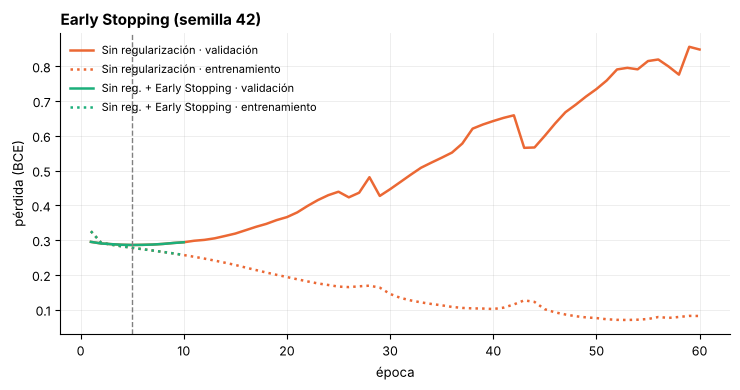

In [ ]:
# Early Stopping: ¿en qué época se detiene y cuánto ahorra?
r_es = r_reg[-1]; r_sin = r_reg[0]
print("Early Stopping -> épocas entrenadas por semilla:", list(r_es["filas"].epocas.astype(int)),
      "| mejor época:", list(r_es["filas"].mejor_epoca.astype(int)))
print(f"Tiempo medio: sin ES = {r_sin['filas'].tiempo_s.mean():.1f} s  vs  con ES = {r_es['filas'].tiempo_s.mean():.1f} s")

fig, ax = plt.subplots(figsize=(7.5, 4))
for i, (r, c) in enumerate([(r_sin, COLORES[1]), (r_es, COLORES[2])]):
    h = r["hist"][0]
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], color=c, label=f"{r['nombre']} · validación")
    ax.plot(range(1, len(h["loss"]) + 1), h["loss"], color=c, ls=":", label=f"{r['nombre']} · entrenamiento")
ax.axvline(int(r_es['filas'].mejor_epoca.iloc[0]), color="gray", ls="--", lw=1)
ax.set_xlabel("época"); ax.set_ylabel("pérdida (BCE)"); ax.set_title("Early Stopping (semilla 42)"); ax.legend(fontsize=8)
plt.tight_layout(); guardar("reg_earlystopping"); plt.show()

### Análisis: regularización (red 256-128-64, 60 épocas, media de 3 semillas)

| Técnica | PR-AUC | F1 óptimo | Pérdida val final | **Degradación** (final − mínima) | Mejor época | Oscilación | Desv. PR-AUC (semillas) | Tiempo (s) |
|---|---|---|---|---|---|---|---|---|
| Sin regularización | 0,294 | 0,343 | 0,912 | **0,627** | 5,3 | 0,0320 | 0,0053 | 31,1 |
| L2 (1e-4) | 0,316 | 0,381 | 0,596 | 0,296 | 7,7 | 0,0161 | 0,0106 | 32,6 |
| **L2 (1e-3)** | 0,448 | 0,485 | 0,298 | **0,002** | 28,7 | 0,0001 | 0,0056 | 31,7 |
| Dropout (0,3) | 0,394 | 0,442 | 0,325 | 0,041 | 12,7 | 0,0026 | 0,0073 | 41,8 |
| BatchNorm | 0,304 | 0,351 | 0,889 | 0,598 | 3,3 | 0,0154 | 0,0132 | 43,9 |
| Dropout + BatchNorm | 0,441 | 0,477 | 0,295 | 0,012 | 18,3 | 0,0010 | 0,0072 | 55,9 |
| L2 + Dropout + BatchNorm | 0,442 | 0,477 | 0,312 | 0,013 | 30,3 | 0,0015 | 0,0031 | 54,9 |
| **Sin reg. + Early Stopping** | **0,455** | **0,488** | 0,292 | 0,007 | 5,3 | 0,0021 | **0,0003** | **5,9** (10 épocas) |

* **El sobreajuste es severo sin regularización:** la mejor pérdida de validación se logra en la época ~5 y a la época 60 ha **empeorado en 0,627** (0,285 → 0,912) mientras la pérdida de entrenamiento baja a ~0,07 (curvas "Sin regularización"). El PR-AUC cae a 0,294, casi la mitad de lo que la misma red logra con regularización (+0,16 al regularizarla). Además la curva de validación es **errática** (oscilación 0,032).
* **Qué funcionó:** **L2 = 1e-3** (degradación casi nula, 0,002, y curva muy suave) y las combinaciones **Dropout + BatchNorm** (0,441) y **L2 + Dropout + BatchNorm** (0,442; la más estable entre semillas, 0,0031) logran PR-AUC 0,44–0,45 y **dejan de empeorar con las épocas**. **Dropout solo** ayuda bastante (0,394) pero no tanto: su pérdida aún sube lentamente.
* **Qué no funcionó:** **L2 = 1e-4 es demasiado débil** (0,316) y **BatchNorm sola no evita el sobreajuste** (degradación 0,598, la más inestable entre semillas: 0,0132). BatchNorm acelera el aprendizaje (su mejor época es la 3,3) pero no limita la capacidad; ayuda a regularizar *combinada* con Dropout. Nota de lectura: la pérdida de entrenamiento con L2 incluye el término de penalización y la de Dropout/BatchNorm se mide con neuronas apagadas, por eso las curvas de entrenamiento de esas variantes no son directamente comparables con la de "sin regularización"; la comparación justa es la **pérdida de validación**.
* **Early Stopping fue la técnica más eficiente:** mejor PR-AUC (0,455), menor variabilidad entre semillas (0,0003) y un **tiempo 5× menor** (5,9 s vs 31,1 s), deteniéndose en ~10 épocas con la mejor en la época ~5. Tiene sentido: ataca directamente el síntoma (la validación deja de mejorar). A cambio, no cambia el modelo y exige un conjunto de validación.
* **Costo:** Dropout y BatchNorm aumentan el tiempo por época (41,8–55,9 s vs 31,1 s).
* **Data augmentation:** no se aplica (es una técnica para imágenes/audio; en datos tabulares no hay transformaciones que preserven la etiqueta).
* **Decisión para el modelo final:** combinar **BatchNorm + Dropout + L2 (1e-4) + Early Stopping**: las tres primeras estabilizan el entrenamiento y permiten una red de más capacidad; Early Stopping fija automáticamente la cantidad de épocas y ahorra tiempo. El valor de dropout y L2 se afina en la sección 7.

### 6.3 Inicialización de pesos
Los pesos iniciales son el **punto de partida** del descenso del gradiente. Inicializar todo en cero hace que todas las neuronas de una capa sean idénticas (reciben el mismo gradiente y nunca se diferencian); pesos demasiado grandes provocan **explosión** del gradiente y demasiado pequeños su **desvanecimiento** (material 1.5.1). Las reglas modernas escalan la varianza según el tamaño de la capa: **Xavier/Glorot** (para sigmoide/tanh) y **He** (para ReLU). Comparamos con ReLU (base):

Experimento: inicialización de pesos (ReLU)


  · Ceros                        PR-AUC=0.117  F1*=0.209  (2,847s acumulados)


  · Normal(0, σ=1) — demasiado grande PR-AUC=0.419  F1*=0.456  (2,901s acumulados)


  · He normal                    PR-AUC=0.430  F1*=0.474  (2,953s acumulados)


,Accuracy,Precision,Recall,F1 (umbral 0.5),F1 (umbral óptimo),PR-AUC,± PR-AUC,ROC-AUC,val_loss,épocas,tiempo (s)
configuración,,,,,,,,,,,
Ceros,0.883,0.000,0.000,0.000,0.209,0.117,0.000,0.499,0.361,40.0,15.779
"Normal(0, σ=1) — demasiado grande",0.893,0.607,0.235,0.338,0.456,0.419,0.001,0.778,0.298,40.0,16.942
Glorot uniforme (base),0.894,0.596,0.282,0.382,0.472,0.433,0.002,0.792,0.294,40.0,14.952
He normal,0.893,0.592,0.266,0.367,0.474,0.430,0.002,0.788,0.295,40.0,16.166


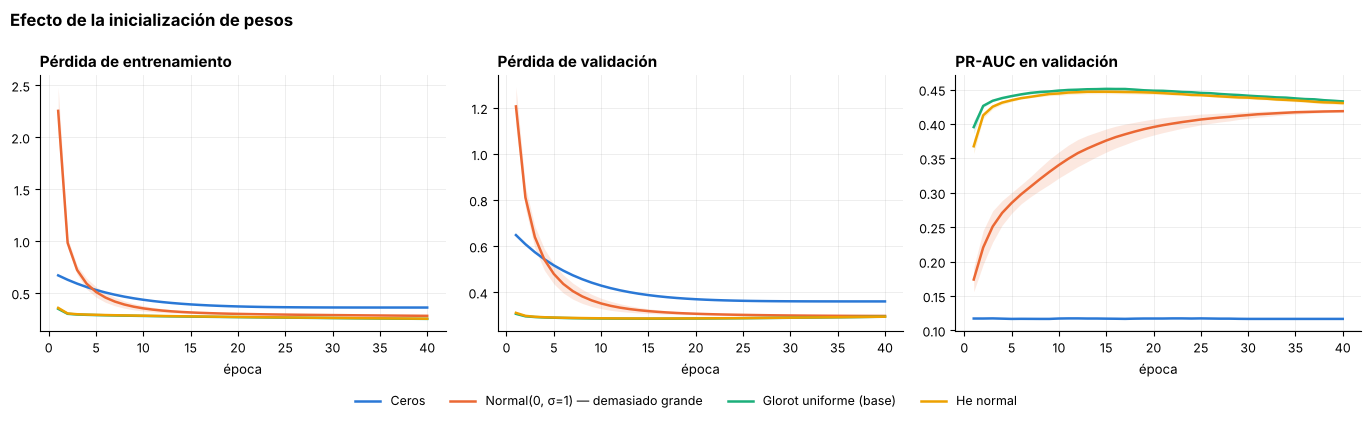

In [ ]:
print("Experimento: inicialización de pesos (ReLU)")
r_init = [
    correr("Ceros", {"init": "zeros"}),
    correr("Normal(0, σ=1) — demasiado grande", {"init": "normal_std1"}),
    {**r_base, "nombre": "Glorot uniforme (base)"},
    correr("He normal", {"init": "he_normal"}),
]
display(tabla(r_init, "init"))
grafico_curvas(r_init, "Efecto de la inicialización de pesos", "init_curvas")

### Análisis: inicialización de pesos (ReLU, 40 épocas)

| Inicialización | PR-AUC | F1 óptimo | Precision / Recall (0.5) |
|---|---|---|---|
| **Ceros** | **0,117** | 0,209 | 0,000 / 0,000 |
| Normal (σ = 1), "demasiado grande" | 0,419 | 0,456 | 0,607 / 0,235 |
| Glorot uniforme (base) | **0,433** | 0,472 | 0,596 / 0,282 |
| He normal | 0,430 | 0,474 | 0,592 / 0,266 |

* **Ceros: la red no aprende.** PR-AUC = 0,117 es exactamente la proporción de positivos (azar) y Precision/Recall = 0. Con todos los pesos iguales, todas las neuronas de una capa calculan lo mismo y reciben el mismo gradiente: **nunca se diferencian** (problema de simetría). Es la confirmación experimental de lo que dice el material: *inicializar los pesos en cero hace que el descenso del gradiente nunca comience a bajar* (los *bias* sí pueden iniciar en cero).
* **σ = 1 es peor** que las reglas escaladas (0,419 vs 0,430–0,433): activaciones grandes al inicio saturan/desbalancean el gradiente. La pérdida es modesta en una red de 2 capas pero crece con la profundidad (ver demostración de 12 capas en 5.2).
* **Glorot vs He son equivalentes aquí** (0,433 vs 0,430): He fue diseñada para ReLU en redes **profundas**; en 2 capas la diferencia es despreciable. **Decisión:** se mantiene **Glorot uniforme** (la opción por defecto de Keras) en el modelo final, porque no hay diferencia medible con He en esta red de 2 capas; si se profundizara la red con ReLU (como la de 12 capas de la sección 5.2) se usaría **He**.

## 7. Análisis de hiperparámetros y reentrenamiento del modelo

### 7.1 Estrategia de búsqueda
Los experimentos de las secciones 4–6 variaron **un parámetro a la vez**, lo que identifica efectos individuales pero **no captura interacciones** (p. ej. un *dropout* alto puede requerir más neuronas o más épocas). Para refinar, hacemos una **búsqueda aleatoria** (Bergstra & Bengio, 2012: suele superar a la grilla con el mismo presupuesto) sobre un espacio construido a partir de lo aprendido:

| Hiperparámetro | Valores |
|---|---|
| Arquitectura | 32 · 64 · 64-32 · 128-64 · 128-64-32 · 256-128-64 |
| Dropout | 0 · 0,1 · 0,2 · 0,3 · 0,5 |
| L2 | 0 · 1e-5 · 1e-4 · 1e-3 |
| Tasa de aprendizaje (Adam) | 3e-4 · 1e-3 · 3e-3 |
| Batch | 128 · 256 · 512 · 1024 |
| Batch Normalization | sí / no |
| Pesos de clase | sí / no |

**Protocolo (sin hacer trampa):**
1. 20 configuraciones al azar, **1 semilla**, hasta 60 épocas con **Early Stopping** sobre el PR-AUC de validación (paciencia 6) → ranking rápido.
2. Las **3 mejores** se repiten con `N_SEEDS` semillas para descartar que ganen por suerte.
3. Se elige la ganadora por **PR-AUC medio en validación**. El conjunto de **prueba no se toca** hasta la sección 8.

In [ ]:
print("Búsqueda aleatoria de hiperparámetros (20 configuraciones, 1 semilla)")
ESPACIO = dict(capas=[(32,), (64,), (64, 32), (128, 64), (128, 64, 32), (256, 128, 64)],
               dropout=[0.0, 0.1, 0.2, 0.3, 0.5], l2=[0.0, 1e-5, 1e-4, 1e-3], lr=[3e-4, 1e-3, 3e-3],
               batch=[128, 256, 512, 1024], batchnorm=[False, True], pesos=[False, True])
rng = np.random.default_rng(7)
N_BUSQ = 20
KW_BUSQ = dict(epochs=60, monitor="val_pr_auc", paciencia=6)

def split_cfg(c):
    return ({k: c[k] for k in ["capas", "dropout", "l2", "lr", "batchnorm"]}, dict(batch=c["batch"], pesos=c["pesos"], **KW_BUSQ))

filas_b, vistos = [], set()
while len(filas_b) < N_BUSQ:
    c = {n: v[int(rng.integers(len(v)))] for n, v in ESPACIO.items()}
    clave = str(c)
    if clave in vistos: continue
    vistos.add(clave)
    cfg_m, kw = split_cfg(c)
    m, h, p, dur, be = entrenar(datos, cfg_m, SEED, **kw)
    thr, f1o = umbral_optimo(datos["yva"], p)
    filas_b.append({**{k: (str(v) if k == "capas" else v) for k, v in c.items()}, "PR-AUC": average_precision_score(datos["yva"], p),
                    "F1 (óptimo)": f1o, "mejor época": be, "tiempo (s)": dur, "_cfg": c})
    keras.backend.clear_session()
    print(f"  {len(filas_b):>2}/{N_BUSQ}  PR-AUC={filas_b[-1]['PR-AUC']:.3f}  F1*={f1o:.3f}  {c['capas']} do={c['dropout']} l2={c['l2']} lr={c['lr']} bs={c['batch']} bn={c['batchnorm']} pw={c['pesos']}")
busq = pd.DataFrame(filas_b).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
tabla_busq = busq.drop(columns="_cfg").round(3)
for c in ["l2", "lr"]:
    tabla_busq[c] = busq[c].map("{:g}".format)   # sin redondear: l2 = 1e-4 no debe verse como 0.000
display(tabla_busq)
RESULTADOS["busqueda"] = json.loads(busq.drop(columns="_cfg").round(4).to_json(orient="records"))

Búsqueda aleatoria de hiperparámetros (20 configuraciones, 1 semilla)


   1/20  PR-AUC=0.458  F1*=0.487  (256, 128, 64) do=0.3 l2=0.0001 lr=0.003 bs=512 bn=True pw=True


   2/20  PR-AUC=0.449  F1*=0.483  (64,) do=0.0 l2=1e-05 lr=0.0003 bs=1024 bn=True pw=False


   3/20  PR-AUC=0.457  F1*=0.484  (64, 32) do=0.5 l2=0.0 lr=0.003 bs=128 bn=False pw=True


   4/20  PR-AUC=0.457  F1*=0.489  (64,) do=0.1 l2=1e-05 lr=0.003 bs=256 bn=True pw=False


...

  17/20  PR-AUC=0.448  F1*=0.485  (64, 32) do=0.5 l2=1e-05 lr=0.001 bs=512 bn=True pw=False


  18/20  PR-AUC=0.458  F1*=0.489  (128, 64) do=0.2 l2=0.0001 lr=0.001 bs=512 bn=True pw=True


  19/20  PR-AUC=0.449  F1*=0.488  (256, 128, 64) do=0.0 l2=0.0001 lr=0.001 bs=256 bn=False pw=False


  20/20  PR-AUC=0.441  F1*=0.481  (64, 32) do=0.5 l2=0.0 lr=0.001 bs=1024 bn=True pw=False


,capas,dropout,l2,lr,batch,batchnorm,pesos,PR-AUC,F1 (óptimo),mejor época,tiempo (s)
0,"(128, 64)",0.5,0.0001,0.001,512,True,False,0.459,0.493,55,27.172
1,"(256, 128, 64)",0.1,0.0001,0.001,256,False,True,0.459,0.493,8,13.212
2,"(128, 64)",0.2,0.0001,0.001,512,True,True,0.458,0.489,20,13.560
3,"(128, 64, 32)",0.2,0,0.0003,512,True,True,0.458,0.491,57,33.503
4,"(256, 128, 64)",0.3,0.0001,0.003,512,True,True,0.458,0.487,10,12.907
5,"(64, 32)",0.5,0,0.003,128,False,True,0.457,0.484,16,14.689
6,"(64,)",0.1,1e-05,0.003,256,True,False,0.457,0.489,9,7.159
7,"(128, 64, 32)",0.3,0.0001,0.001,1024,False,False,0.457,0.489,45,15.844
8,"(32,)",0.0,0.0001,0.003,256,True,True,0.454,0.484,11,7.840
9,"(256, 128, 64)",0.0,0.001,0.001,128,False,False,0.454,0.486,23,26.242


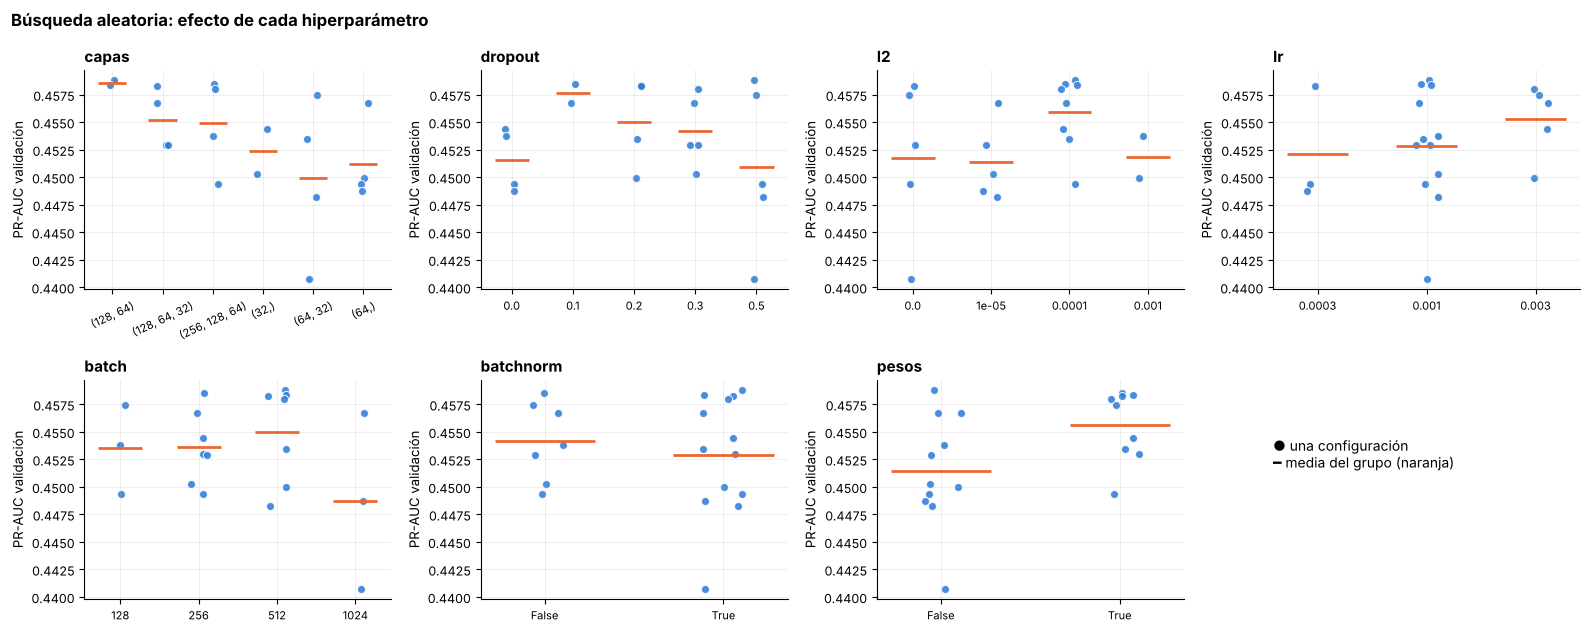

In [ ]:
# ¿Qué hiperparámetros importan? PR-AUC de las 20 configuraciones según el valor de cada hiperparámetro
fig, axs = plt.subplots(2, 4, figsize=(16, 6.4))
jit = np.random.default_rng(0)
for ax, nombre in zip(axs.ravel(), ["capas", "dropout", "l2", "lr", "batch", "batchnorm", "pesos"]):
    vals = sorted(busq[nombre].unique(), key=lambda v: (str(type(v)), v))
    for j, v in enumerate(vals):
        ys = busq.loc[busq[nombre] == v, "PR-AUC"].values
        ax.scatter(np.full(len(ys), j) + jit.uniform(-0.12, 0.12, len(ys)), ys, s=34, color=COLORES[0], alpha=0.85, edgecolor="white", lw=0.8)
        ax.hlines(ys.mean(), j - 0.28, j + 0.28, color=COLORES[1], lw=2)
    ax.set_xticks(range(len(vals))); ax.set_xticklabels([str(v) for v in vals], rotation=25 if nombre == "capas" else 0, fontsize=8)
    ax.set_title(nombre); ax.set_ylabel("PR-AUC validación")
ax = axs.ravel()[-1]; ax.axis("off")
ax.text(0, 0.6, "● una configuración\n━ media del grupo (naranja)", fontsize=10)
plt.suptitle("Búsqueda aleatoria: efecto de cada hiperparámetro", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(); guardar("busqueda_hiperparametros"); plt.show()

In [ ]:
print("Reevaluación de las 3 mejores configuraciones con", N_SEEDS, "semillas (+ referencia: base con Early Stopping)")
r_top = []
for i in range(3):
    c = busq.loc[i, "_cfg"]; cfg_m, kw = split_cfg(c)
    r_top.append(correr(f"Top {i+1}: {c['capas']} do={c['dropout']} l2={c['l2']} lr={c['lr']:g} bs={c['batch']} bn={int(c['batchnorm'])} pw={int(c['pesos'])}", cfg_m, **kw))
r_top.append(correr("Referencia: base 64-32 + ES", {}, **KW_BUSQ))
t_top = tabla(r_top, "top3")
display(t_top)

# configuración ganadora = mayor PR-AUC medio entre las 3 candidatas
ganador = int(np.argmax([r["filas"].pr_auc.mean() for r in r_top[:3]]))
MEJOR = busq.loc[ganador, "_cfg"]
CFG_FINAL, KW_FINAL = split_cfg(MEJOR)
print("\nCONFIGURACIÓN FINAL:", MEJOR)
RESULTADOS["config_final"] = {k: (list(v) if isinstance(v, tuple) else v) for k, v in MEJOR.items()}

Reevaluación de las 3 mejores configuraciones con 3 semillas (+ referencia: base con Early Stopping)


  · Top 1: (128, 64) do=0.5 l2=0.0001 lr=0.001 bs=512 bn=1 pw=0 PR-AUC=0.453  F1*=0.488  (3,392s acumulados)


  · Top 2: (256, 128, 64) do=0.1 l2=0.0001 lr=0.001 bs=256 bn=0 pw=1 PR-AUC=0.458  F1*=0.491  (3,431s acumulados)


  · Top 3: (128, 64) do=0.2 l2=0.0001 lr=0.001 bs=512 bn=1 pw=1 PR-AUC=0.463  F1*=0.493  (3,481s acumulados)


  · Referencia: base 64-32 + ES  PR-AUC=0.452  F1*=0.485  (3,517s acumulados)


,Accuracy,Precision,Recall,F1 (umbral 0.5),F1 (umbral óptimo),PR-AUC,± PR-AUC,ROC-AUC,val_loss,épocas,tiempo (s)
configuración,,,,,,,,,,,
"Top 1: (128, 64) do=0.5 l2=0.0001 lr=0.001 bs=512 bn=1 pw=0",0.894,0.641,0.220,0.327,0.488,0.453,0.004,0.802,0.292,50.667,23.503
"Top 2: (256, 128, 64) do=0.1 l2=0.0001 lr=0.001 bs=256 bn=0 pw=1",0.812,0.344,0.633,0.442,0.491,0.458,0.003,0.799,0.525,14.000,11.610
"Top 3: (128, 64) do=0.2 l2=0.0001 lr=0.001 bs=512 bn=1 pw=1",0.795,0.318,0.652,0.427,0.493,0.463,0.004,0.801,0.527,30.000,15.431
Referencia: base 64-32 + ES,0.895,0.626,0.251,0.358,0.485,0.452,0.003,0.799,0.287,21.333,10.524



CONFIGURACIÓN FINAL: {'capas': (128, 64), 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.001, 'batch': 512, 'batchnorm': True, 'pesos': True}


### Análisis de la búsqueda de hiperparámetros

* **El paisaje es muy plano.** Las 20 configuraciones aleatorias obtienen PR-AUC entre **0,441 y 0,459** (desv. estándar 0,0047, parecida al ruido entre semillas ≈ 0,004). Es decir: casi cualquier combinación *razonable* de regularización + Early Stopping rinde parecido, y **el límite lo pone la señal de los datos**, no el afinamiento fino. Esto es coherente con lo visto en las secciones 4 a 6: lo que más movía el resultado era evitar el sobreajuste (+0,16 de PR-AUC), no ajustar la arquitectura o el optimizador.
* **Efectos por hiperparámetro (PR-AUC medio, todos pequeños):** pesos de clase con 0,4557 vs 0,4515 sin pesos; L2 = 1e-4 con 0,4560 vs 0,4516 sin L2; batch 512 con 0,4550 y batch 1024 el peor con 0,4487; arquitecturas de 2–3 capas (128-64: 0,4586) algo mejores que 1 capa (0,4512); dropout 0,1–0,3 (0,454–0,458) mejor que 0 (0,4516) o 0,5 (0,4509). Con tan pocas configuraciones y diferencias tan chicas, estas tendencias son **indicios, no pruebas**.
* **Maldición del ganador:** la mejor configuración con 1 semilla (128-64, dropout 0,5, sin pesos; 0,459) bajó a **0,453** al promediar 3 semillas, mientras la que quedó 3.ª (128-64, dropout 0,2, con pesos) subió a **0,463**. Elegir con una sola corrida habría sido tomar ruido por señal; por eso el protocolo reevalúa las 3 mejores con varias semillas.
* **Configuración ganadora:** MLP **128-64**, **Dropout 0,2**, **L2 1e-4**, **BatchNorm**, Adam **lr 1e-3**, **batch 512**, **pesos de clase**, Early Stopping (PR-AUC val., paciencia 6). Mejora al modelo base con Early Stopping (0,452) en **+0,011** de PR-AUC (≈ 3 desviaciones entre semillas): una mejora **real pero pequeña**.

### 7.2 Confirmación de la función de activación sobre la configuración final
La comparación de la sección 5.1 se hizo con la red base y **épocas fijas**, y ya vimos que con épocas fijas el resultado se mezcla con *qué tan rápido sobreajusta* cada configuración. Por eso, ahora que tenemos la configuración final (con regularización y Early Stopping), **repetimos la comparación de activaciones sobre ella**. Regla de decisión fijada de antemano: *se elige la activación con mayor PR-AUC medio en validación*; si hay empate práctico se prefiere ReLU por simplicidad y costo.

Confirmación de la función de activación sobre la configuración final


  · ReLU                         PR-AUC=0.463  F1*=0.493  (50s acumulados)


  · ELU                          PR-AUC=0.459  F1*=0.485  (130s acumulados)


  · Leaky ReLU                   PR-AUC=0.461  F1*=0.490  (186s acumulados)


  · Tanh                         PR-AUC=0.455  F1*=0.486  (256s acumulados)


,Accuracy,Precision,Recall,F1 (umbral 0.5),F1 (umbral óptimo),PR-AUC,± PR-AUC,ROC-AUC,val_loss,épocas,tiempo (s)
configuración,,,,,,,,,,,
ReLU,0.795,0.318,0.652,0.427,0.493,0.463,0.004,0.801,0.527,30.000,15.503
ELU,0.796,0.320,0.654,0.429,0.485,0.459,0.002,0.802,0.536,50.000,26.369
Leaky ReLU,0.801,0.326,0.656,0.436,0.490,0.461,0.001,0.802,0.534,39.000,18.110
Tanh,0.804,0.329,0.646,0.436,0.486,0.455,0.004,0.793,0.509,47.333,22.580


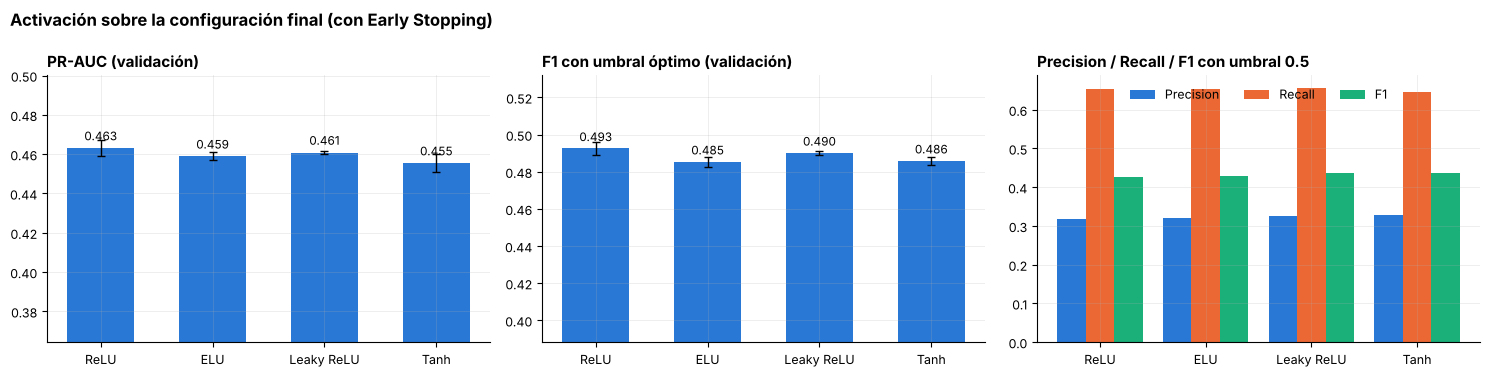


Activación elegida: relu | Configuración final: {'capas': (128, 64), 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.001, 'batchnorm': True, 'activacion': 'relu'} {'batch': 512, 'pesos': True, 'epochs': 60, 'monitor': 'val_pr_auc', 'paciencia': 6}


In [ ]:
print("Confirmación de la función de activación sobre la configuración final")
cands = {"ReLU": "relu", "ELU": "elu", "Leaky ReLU": "leaky_relu", "Tanh": "tanh"}
r_actf = [correr(n, {**CFG_FINAL, "activacion": a}, **KW_FINAL) for n, a in cands.items()]
display(tabla(r_actf, "activacion_final"))
grafico_barras(r_actf, "Activación sobre la configuración final (con Early Stopping)", "act_final_barras", rot=0)

pr_medios = [r["filas"].pr_auc.mean() for r in r_actf]
mejor_act = list(cands.values())[int(np.argmax(pr_medios))]
if mejor_act != "relu" and max(pr_medios) - pr_medios[0] < 0.003:      # empate práctico -> ReLU
    mejor_act = "relu"
CFG_FINAL = {**CFG_FINAL, "activacion": mejor_act}
RESULTADOS["config_final"] = {**RESULTADOS["config_final"], "activacion": mejor_act}
print("\nActivación elegida:", mejor_act, "| Configuración final:", CFG_FINAL, KW_FINAL)

### Análisis: activación sobre la configuración final

| Activación | PR-AUC | ± | F1 óptimo | Épocas hasta detenerse | Tiempo (s) |
|---|---|---|---|---|---|
| **ReLU** | **0,463** | 0,004 | **0,493** | 30 | **15,5** |
| Leaky ReLU | 0,461 | 0,001 | 0,490 | 39 | 18,1 |
| ELU | 0,459 | 0,002 | 0,485 | 50 | 26,4 |
| Tanh | 0,455 | 0,004 | 0,486 | 47 | 22,6 |

* Con regularización y Early Stopping **la ventaja que ELU mostraba en la sección 5.1 desaparece** (0,459 vs 0,463): era un efecto de la comparación a épocas fijas, no una superioridad real. Las cuatro quedan a ≤ 0,008 de PR-AUC (1–2 desviaciones entre semillas).
* **ReLU obtiene el mayor PR-AUC y además es la más rápida** (se detiene en ~30 épocas y ~15 s, frente a 47–50 épocas y 23–26 s de ELU/tanh). Cumple la regla fijada de antemano, por lo que **se confirma ReLU**. Justificación técnica adicional: derivada 1 para $u>0$ (el gradiente no se desvanece), cálculo muy barato y es la activación estándar hoy (material 1.2.1).

## 8. Evaluación del modelo final

### 8.1 Reentrenamiento y umbral de decisión
Se reentrena la configuración ganadora (semilla 42) con Early Stopping sobre validación. Como las clases están desbalanceadas, el umbral 0,5 no es el mejor corte: elegimos el **umbral que maximiza el F1 en validación** y lo aplicamos **sin cambios** sobre el conjunto de **prueba** (que el modelo y las decisiones de diseño nunca vieron). Para dimensionar el valor del MLP, lo comparamos en prueba contra:

* **Siempre "no"** (la estrategia trivial: ~88 % de Accuracy sin aprender nada);
* **Regresión logística** (un modelo lineal sencillo; si la red no la supera, la complejidad extra no se justifica);
* **MLP base** (64-32, sin optimización ni regularización).

In [ ]:
# ---- Modelos a evaluar ----
modelo_f, hist_f, p_va_f, dur_f, be_f = entrenar(datos, CFG_FINAL, SEED, **KW_FINAL)
modelo_b, hist_b, p_va_b, dur_b, be_b = entrenar(datos, {}, SEED)            # base sin optimización
p_te_f, p_te_b = proba(modelo_f, datos["Xte"]), proba(modelo_b, datos["Xte"])

lr_model = LogisticRegression(max_iter=2000).fit(datos["Xtr"], datos["ytr"])
p_va_l, p_te_l = lr_model.predict_proba(datos["Xva"])[:, 1], lr_model.predict_proba(datos["Xte"])[:, 1]

thr_f, _ = umbral_optimo(datos["yva"], p_va_f)
thr_b, _ = umbral_optimo(datos["yva"], p_va_b)
thr_l, _ = umbral_optimo(datos["yva"], p_va_l)
print(f"Umbrales elegidos en validación -> MLP final: {thr_f:.2f} | MLP base: {thr_b:.2f} | Reg. logística: {thr_l:.2f}")
print(f"Modelo final: {be_f} épocas útiles, {modelo_f.count_params():,} parámetros\n")

yte = datos["yte"]
filas_t = {
    "Siempre 'no' (trivial)":              metricas(yte, np.zeros(len(yte)), 0.5),
    "Regresión logística (umbral val.)":   metricas(yte, p_te_l, thr_l),
    "MLP base (umbral 0.5)":               metricas(yte, p_te_b, 0.5),
    "MLP base (umbral val.)":              metricas(yte, p_te_b, thr_b),
    "MLP final (umbral 0.5)":              metricas(yte, p_te_f, 0.5),
    "MLP final (umbral val.)":             metricas(yte, p_te_f, thr_f),
}
tab_test = pd.DataFrame(filas_t).T.rename(columns={"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1",
                                                   "pr_auc": "PR-AUC", "roc_auc": "ROC-AUC"}).round(3)
display(tab_test)
RESULTADOS["test"] = json.loads(tab_test.round(4).to_json(orient="index"))
RESULTADOS["umbrales"] = {"final": thr_f, "base": thr_b, "logistica": thr_l}

Umbrales elegidos en validación -> MLP final: 0.71 | MLP base: 0.21 | Reg. logística: 0.22
Modelo final: 20 épocas útiles, 15,489 parámetros



,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC
Siempre 'no' (trivial),0.883,0.000,0.000,0.000,0.117,0.500
Regresión logística (umbral val.),0.876,0.465,0.400,0.430,0.384,0.760
MLP base (umbral 0.5),0.891,0.574,0.259,0.357,0.405,0.789
MLP base (umbral val.),0.859,0.415,0.507,0.457,0.405,0.789
MLP final (umbral 0.5),0.789,0.304,0.629,0.410,0.424,0.795
MLP final (umbral val.),0.875,0.465,0.458,0.461,0.424,0.795


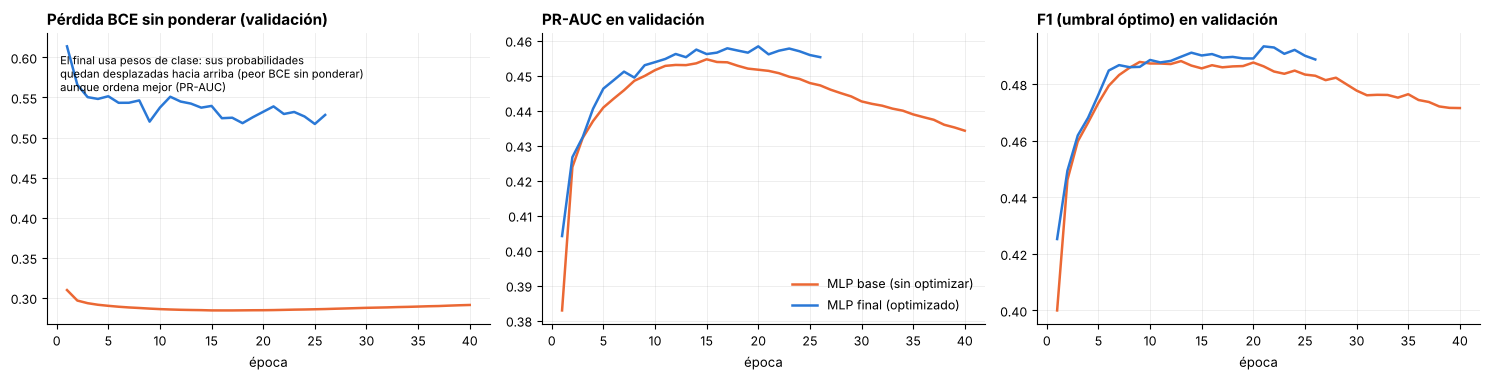

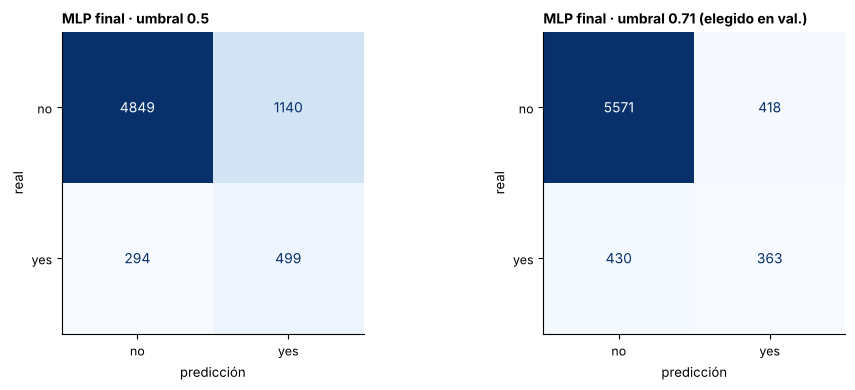

In [ ]:
# ---- Gráfico "con y sin optimización": base vs modelo final ----
# Nota: el modelo final se entrena con pesos de clase, por lo que su pérdida de ENTRENAMIENTO no es comparable con la del base.
# Se grafican métricas de validación (misma definición para ambos modelos).
fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
for h, nom, c in [(hist_b, "MLP base (sin optimizar)", COLORES[1]), (hist_f, "MLP final (optimizado)", COLORES[0])]:
    axs[0].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], color=c, label=nom)
    axs[1].plot(range(1, len(h["val_pr_auc"]) + 1), h["val_pr_auc"], color=c, label=nom)
    axs[2].plot(range(1, len(h["val_f1_max"]) + 1), h["val_f1_max"], color=c, label=nom)
axs[0].set_title("Pérdida BCE sin ponderar (validación)"); axs[1].set_title("PR-AUC en validación"); axs[2].set_title("F1 (umbral óptimo) en validación")
for a in axs: a.set_xlabel("época")
axs[0].text(0.03, 0.93, "El final usa pesos de clase: sus probabilidades\nquedan desplazadas hacia arriba (peor BCE sin ponderar)\naunque ordena mejor (PR-AUC)", transform=axs[0].transAxes, fontsize=8, va="top")
axs[1].legend(); plt.tight_layout(); guardar("final_base_vs_final"); plt.show()

# ---- Matrices de confusión (prueba) ----
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, (tit, p, thr) in zip(axs, [(f"MLP final · umbral 0.5", p_te_f, 0.5), (f"MLP final · umbral {thr_f:.2f} (elegido en val.)", p_te_f, thr_f)]):
    cm = confusion_matrix(yte, (p >= thr).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["no", "yes"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(tit, fontsize=10); ax.grid(False); ax.set_xlabel("predicción"); ax.set_ylabel("real")
plt.tight_layout(); guardar("final_matrices_confusion"); plt.show()

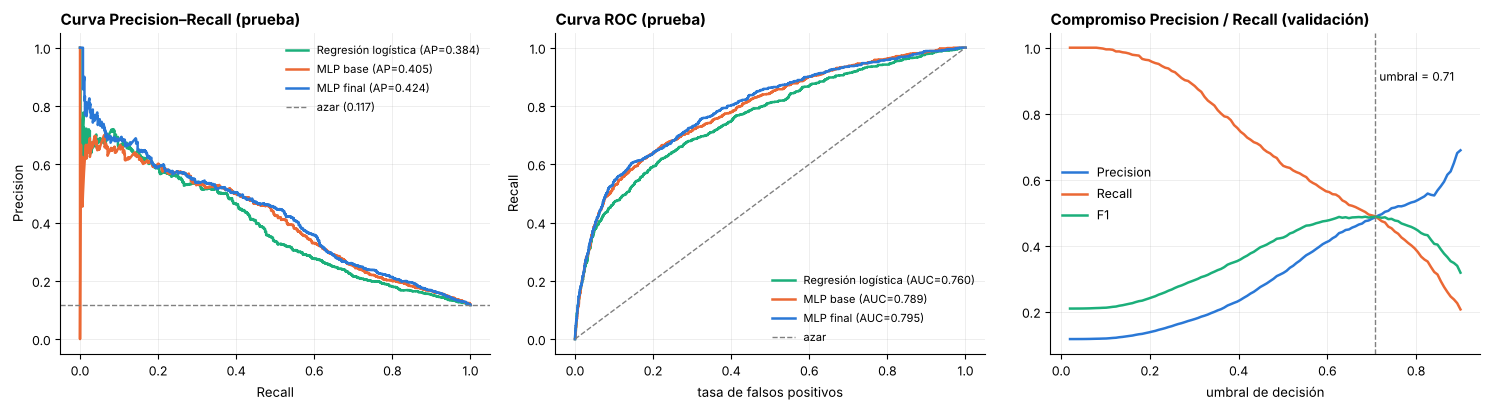

In [ ]:
# ---- Curvas PR y ROC en prueba, y barrido de umbral en validación ----
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for nom, p, c in [("Regresión logística", p_te_l, COLORES[2]), ("MLP base", p_te_b, COLORES[1]), ("MLP final", p_te_f, COLORES[0])]:
    pr, rc, _ = precision_recall_curve(yte, p); axs[0].plot(rc, pr, color=c, label=f"{nom} (AP={average_precision_score(yte, p):.3f})")
    fpr, tpr, _ = roc_curve(yte, p); axs[1].plot(fpr, tpr, color=c, label=f"{nom} (AUC={roc_auc_score(yte, p):.3f})")
axs[0].axhline(yte.mean(), color="gray", ls="--", lw=1, label=f"azar ({yte.mean():.3f})")
axs[0].set_xlabel("Recall"); axs[0].set_ylabel("Precision"); axs[0].set_title("Curva Precision–Recall (prueba)"); axs[0].legend(fontsize=8)
axs[1].plot([0, 1], [0, 1], color="gray", ls="--", lw=1, label="azar"); axs[1].set_xlabel("tasa de falsos positivos"); axs[1].set_ylabel("Recall")
axs[1].set_title("Curva ROC (prueba)"); axs[1].legend(fontsize=8)

ths = np.linspace(0.02, 0.9, 120)
pv = np.array([[precision_score(datos["yva"], (p_va_f >= t).astype(int), zero_division=0), recall_score(datos["yva"], (p_va_f >= t).astype(int)),
                f1_score(datos["yva"], (p_va_f >= t).astype(int))] for t in ths])
for k, (nom, c) in enumerate([("Precision", COLORES[0]), ("Recall", COLORES[1]), ("F1", COLORES[2])]):
    axs[2].plot(ths, pv[:, k], color=c, label=nom)
axs[2].axvline(thr_f, color="gray", ls="--", lw=1); axs[2].text(thr_f + 0.01, 0.9, f"umbral = {thr_f:.2f}", fontsize=8.5)
axs[2].set_xlabel("umbral de decisión"); axs[2].set_title("Compromiso Precision / Recall (validación)"); axs[2].legend()
plt.tight_layout(); guardar("final_curvas"); plt.show()

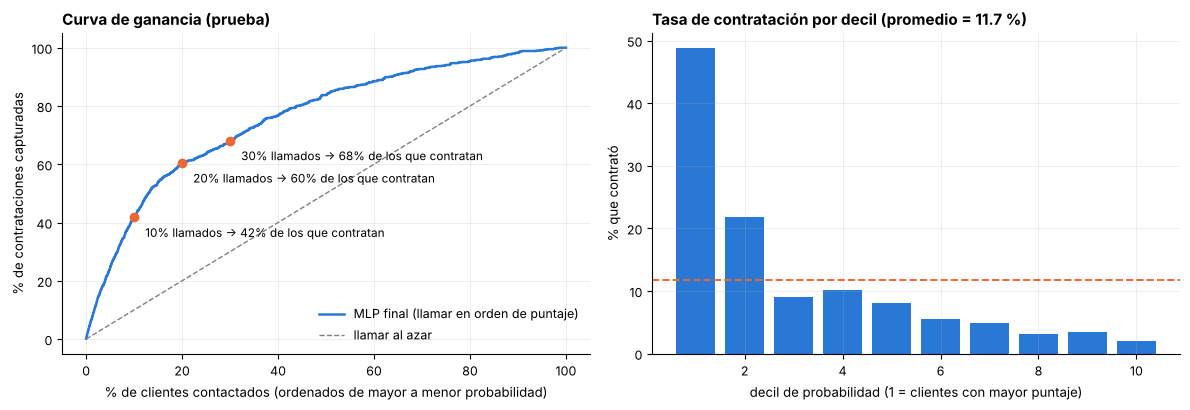

{'top10': 0.41740226986128626, 'top20': 0.6040353089533418, 'top30': 0.6809583858764187, 'tasa_decil1': 48.748159057437405, 'tasa_decil10': 2.0618556701030926}


In [ ]:
# ---- Valor de negocio: curva de ganancia (prueba) ----
orden = np.argsort(-p_te_f)
captura = np.cumsum(yte[orden]) / yte.sum()
frac = np.arange(1, len(yte) + 1) / len(yte)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
axs[0].plot(frac * 100, captura * 100, color=COLORES[0], label="MLP final (llamar en orden de puntaje)")
axs[0].plot([0, 100], [0, 100], color="gray", ls="--", lw=1, label="llamar al azar")
for q in [0.1, 0.2, 0.3]:
    i = int(q * len(yte)); axs[0].scatter([q * 100], [captura[i] * 100], color=COLORES[1], zorder=5)
    axs[0].annotate(f"{q*100:.0f}% llamados → {captura[i]*100:.0f}% de los que contratan", (q * 100, captura[i] * 100), textcoords="offset points", xytext=(8, -14), fontsize=8.5)
axs[0].set_xlabel("% de clientes contactados (ordenados de mayor a menor probabilidad)"); axs[0].set_ylabel("% de contrataciones capturadas")
axs[0].set_title("Curva de ganancia (prueba)"); axs[0].legend(loc="lower right")
decil = pd.DataFrame({"p": p_te_f, "y": yte}); decil["decil"] = pd.qcut(decil.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
tasa_decil = decil.groupby("decil", observed=True).y.mean() * 100
axs[1].bar(tasa_decil.index.astype(int), tasa_decil.values, color=COLORES[0]); axs[1].axhline(yte.mean() * 100, color=COLORES[1], ls="--", lw=1.4)
axs[1].set_xlabel("decil de probabilidad (1 = clientes con mayor puntaje)"); axs[1].set_ylabel("% que contrató"); axs[1].set_title(f"Tasa de contratación por decil (promedio = {yte.mean()*100:.1f} %)")
plt.tight_layout(); guardar("final_ganancia"); plt.show()
RESULTADOS["ganancia"] = {"top10": float(captura[int(0.1*len(yte))]), "top20": float(captura[int(0.2*len(yte))]), "top30": float(captura[int(0.3*len(yte))]),
                          "tasa_decil1": float(tasa_decil.iloc[0]), "tasa_decil10": float(tasa_decil.iloc[-1])}
print(RESULTADOS["ganancia"])

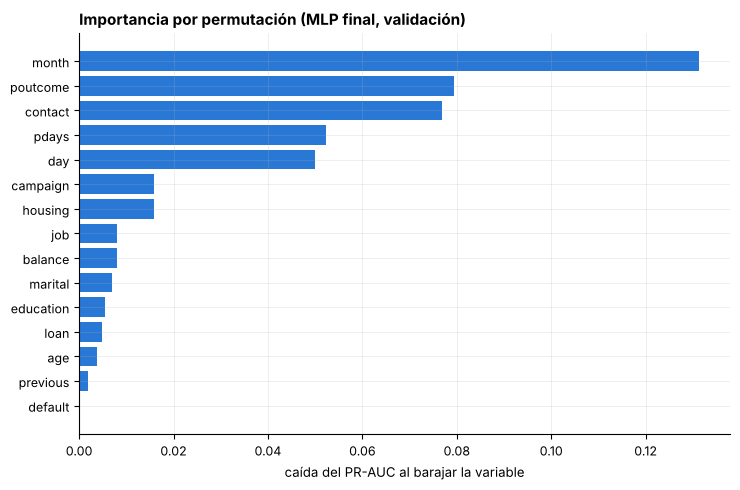

Top 5 variables: ['month', 'poutcome', 'contact', 'pdays', 'day']


In [ ]:
# ---- Importancia de variables por permutación (sobre validación): ¿qué usa la red para decidir? ----
Xva_raw = X.iloc[idx_va].reset_index(drop=True)
base_pr = average_precision_score(datos["yva"], proba(modelo_f, datos["Xva"]))
rng_p = np.random.default_rng(0)
imp = {}
for col in [c for c in X.columns if c != "duration"]:
    caidas = []
    for _ in range(5):
        tmp = Xva_raw.copy(); tmp[col] = rng_p.permutation(tmp[col].values)
        caidas.append(base_pr - average_precision_score(datos["yva"], proba(modelo_f, transformar(datos, tmp))))
    imp[col] = np.mean(caidas)
imp = pd.Series(imp).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(imp.index, imp.values, color=COLORES[0]); ax.set_xlabel("caída del PR-AUC al barajar la variable")
ax.set_title("Importancia por permutación (MLP final, validación)")
plt.tight_layout(); guardar("final_importancia"); plt.show()
print("Top 5 variables:", list(imp.index[::-1][:5]))
RESULTADOS["importancia"] = {k: float(v) for k, v in imp.items()}

### Análisis: resultados finales en el conjunto de prueba (6.782 clientes, 793 contratan)

| Modelo (prueba) | Accuracy | Precision | Recall | **F1** | **PR-AUC** | ROC-AUC |
|---|---|---|---|---|---|---|
| Siempre "no" | 0,883 | 0,000 | 0,000 | 0,000 | 0,117 | 0,500 |
| Regresión logística (umbral val.) | 0,876 | 0,465 | 0,400 | 0,430 | 0,384 | 0,760 |
| MLP base (umbral 0,5) | 0,891 | 0,574 | 0,259 | 0,357 | 0,405 | 0,789 |
| MLP base (umbral val.) | 0,859 | 0,415 | 0,507 | 0,457 | 0,405 | 0,789 |
| MLP final (umbral 0,5) | 0,789 | 0,304 | 0,629 | 0,410 | 0,424 | 0,795 |
| **MLP final (umbral val. = 0,71)** | 0,875 | **0,465** | **0,458** | **0,461** | **0,424** | **0,795** |

1. **La Accuracy no sirve para decidir.** El modelo trivial tiene Accuracy 0,883, *mayor* que la del modelo final (0,875), y sin embargo no detecta a ningún cliente. Con el desbalance, hay que mirar Precision, Recall, F1 y PR-AUC.
2. **El MLP final supera a la regresión logística**, el rival lineal sencillo: con la misma Precision (0,465) detecta más contrataciones (Recall 0,458 vs 0,400), lo que da **F1 +0,031**, **PR-AUC +0,040** (0,424 vs 0,384) y **ROC-AUC +0,035**. Esa ventaja justifica usar una red no lineal, aunque sea moderada (coherente con el control lineal de la sección 5.1: el problema es "casi lineal").
3. **Contra el MLP base la historia es más matizada, y conviene decirla tal cual.** Con cada uno usando su mejor umbral, el F1 es prácticamente idéntico (0,461 vs 0,457: diferencia dentro del ruido). El modelo optimizado mejora el **ranking** (PR-AUC 0,424 vs 0,405, +0,019), es más **estable**, no depende de adivinar el número de épocas y entrena en una fracción del tiempo; pero **no** "multiplica" el F1. La mejora grande del F1 (0,357 → 0,461) viene de **elegir bien el umbral de decisión** (0,5 → valor óptimo en validación), no de la arquitectura.
4. **Efecto del umbral:** con 0,5, el modelo final entrenado con pesos de clase es agresivo (Recall 0,629, Precision 0,304, F1 0,410). El umbral elegido en validación (0,71) equilibra ambas (0,465 / 0,458). Las probabilidades de un modelo con pesos de clase **no están calibradas**, por eso 0,71 y no 0,5 es el punto de equilibrio.
5. **De validación a prueba el PR-AUC bajó** (0,463 → 0,424). Parte es el *"optimismo de selección"* (elegimos la configuración y el momento de parada con ese mismo conjunto) y parte es variabilidad muestral; el valor en prueba cae dentro del rango observado en validación cruzada (0,419–0,473). Por eso reportamos el resultado de **prueba** como la estimación honesta, y la validación cruzada (9.2) como medida de su dispersión.
6. **Valor para el negocio (curva de ganancia):** si se llama a los clientes en orden de probabilidad, el **10 %** de las llamadas captura el **41,7 %** de las contrataciones, el **20 %** captura el **60,4 %** y el **30 %** el **68,1 %**. El decil de mayor puntaje contrata en un **48,7 %** de los casos frente a **2,1 %** en el decil más bajo (promedio 11,7 %). Con el umbral elegido, de cada 100 llamadas **46** terminan en contratación: **4,0 veces más eficiente** que llamar al azar.

## 9. Análisis y mejora: cálculo e interpretación de las métricas

### 9.1 Cómo se calcula cada métrica (con los números reales del modelo final)
Todo parte de la **matriz de confusión** de la clase positiva ("yes" = contrata):

|  | Predice **no** | Predice **yes** |
|---|---|---|
| **Real no** | VN (verdaderos negativos) | **FP** (falsos positivos: llamamos y no compra) |
| **Real yes** | **FN** (falsos negativos: no llamamos y habría comprado) | VP (verdaderos positivos: llamamos y compra) |

$$\text{Accuracy}=\frac{VP+VN}{VP+VN+FP+FN}\qquad \text{Precision}=\frac{VP}{VP+FP}\qquad \text{Recall}=\frac{VP}{VP+FN}\qquad F_1=\frac{2\cdot P\cdot R}{P+R}$$

* **Accuracy**: fracción de aciertos totales. **Engañosa** con clases desbalanceadas (el material 1.4.2 indica que "funciona muy bien cuando las clases están equilibradas", que no es este caso).
* **Precision**: de los clientes a los que *decidimos llamar*, ¿qué fracción realmente contrata? (mide el **costo de llamadas desperdiciadas**).
* **Recall**: de todos los que *habrían contratado*, ¿qué fracción detectamos? (mide las **oportunidades perdidas**).
* **F1**: media armónica de Precision y Recall; es baja si cualquiera de las dos es baja.

In [ ]:
# Cálculo manual de cada métrica a partir de la matriz de confusión (MLP final, prueba, umbral elegido en validación)
yhat = (p_te_f >= thr_f).astype(int)
VN, FP, FN, VP = confusion_matrix(yte, yhat).ravel()
accuracy  = (VP + VN) / (VP + VN + FP + FN)
precision = VP / (VP + FP)
recall    = VP / (VP + FN)
f1        = 2 * precision * recall / (precision + recall)

print(f"VN = {VN:,} | FP = {FP:,} | FN = {FN:,} | VP = {VP:,}   (total = {len(yte):,})".replace(",", "."))
print(f"Accuracy  = ({VP} + {VN}) / {len(yte)} = {accuracy:.3f}")
print(f"Precision = {VP} / ({VP} + {FP}) = {precision:.3f}   -> de cada 100 llamadas, {precision*100:.0f} terminan en contratación")
print(f"Recall    = {VP} / ({VP} + {FN}) = {recall:.3f}   -> detectamos {recall*100:.0f} de cada 100 clientes que contratarían")
print(f"F1        = 2·{precision:.3f}·{recall:.3f} / ({precision:.3f}+{recall:.3f}) = {f1:.3f}")

# Verificación contra scikit-learn
assert abs(accuracy - accuracy_score(yte, yhat)) < 1e-9 and abs(precision - precision_score(yte, yhat)) < 1e-9
assert abs(recall - recall_score(yte, yhat)) < 1e-9 and abs(f1 - f1_score(yte, yhat)) < 1e-9
print("\nVerificado: coincide con scikit-learn.")

# Ejemplo ilustrativo de por qué Accuracy engaña
acc_trivial = 1 - yte.mean()
print(f"\nEl modelo trivial 'siempre no' tiene Accuracy = {acc_trivial:.3f} pero Recall = 0.000 (no detecta a nadie).")
print(f"Llamar a TODOS los clientes: precision = {yte.mean():.3f} (solo {yte.mean()*100:.1f} de cada 100 llamadas sirven).")
print(f"Con el modelo: precision = {precision:.3f} -> {precision/yte.mean():.1f}x más eficiente (lift).")
RESULTADOS["matriz_confusion"] = dict(VN=int(VN), FP=int(FP), FN=int(FN), VP=int(VP), lift=float(precision / yte.mean()))

VN = 5.571 | FP = 418 | FN = 430 | VP = 363   (total = 6.782)
Accuracy  = (363 + 5571) / 6782 = 0.875
Precision = 363 / (363 + 418) = 0.465   -> de cada 100 llamadas, 46 terminan en contratación
Recall    = 363 / (363 + 430) = 0.458   -> detectamos 46 de cada 100 clientes que contratarían
F1        = 2·0.465·0.458 / (0.465+0.458) = 0.461

Verificado: coincide con scikit-learn.

El modelo trivial 'siempre no' tiene Accuracy = 0.883 pero Recall = 0.000 (no detecta a nadie).
Llamar a TODOS los clientes: precision = 0.117 (solo 11.7 de cada 100 llamadas sirven).
Con el modelo: precision = 0.465 -> 4.0x más eficiente (lift).


### Interpretación de las métricas y propuestas de mejora

**¿Qué significan los números del modelo final?** (prueba, umbral 0,71)

* **Matriz de confusión:** VN = 5.571, FP = 418, FN = 430, VP = 363. Se detectaron 363 de los 793 clientes que contratarían (**Recall 0,458**) y se evitaron 5.571 llamadas a clientes que no iban a contratar, pero se hicieron 418 llamadas "en vano" (**Precision 0,465**: de cada 100 llamadas, 46 aciertan).
* **Equilibrio Precision/Recall:** son dos errores con costos distintos para el banco: un **falso positivo** es una llamada desperdiciada; un **falso negativo** es una venta perdida. El F1 (0,461) los pondera por igual. Si una contratación vale mucho más que una llamada, conviene **bajar el umbral** (más Recall, menos Precision): la curva de la sección 8.1 muestra, por ejemplo, que a 0,50 el Recall sube a ~0,63 y la Precision baja a ~0,30. La decisión óptima no es técnica, es de **costo/beneficio**.

**¿Cómo mejorar Precision y Recall?** Hay dos tipos de palanca:

1. **Mover el punto de operación sobre la misma curva** (cambiar el umbral): sube una a costa de la otra. Propuesta: elegir el umbral por **valor esperado** (llamar si $p \cdot \text{beneficio} > \text{costo}$), previa **calibración** de las probabilidades (Platt o regresión isotónica), porque el modelo con pesos de clase no entrega probabilidades calibradas.
2. **Mover la curva completa** (que mejoren ambas a la vez): requiere más información o mejores modelos. Propuestas: (a) comparar con **árboles potenciados** (XGBoost/LightGBM), que suelen ser muy competitivos en datos tabulares; (b) **ingeniería de variables** (interacciones edad×ocupación, historial de contactos) o *embeddings* para las categóricas; (c) **ensamble** de varias redes con distintas semillas (promediar reduce la varianza visible en la validación cruzada); (d) técnicas de remuestreo (*SMOTE*/submuestreo) como alternativa a los pesos de clase; (e) **más datos o variables** del cliente (el techo lo marca la señal disponible).

**Lectura crítica de las variables importantes:** `month` (por lejos), `poutcome`, `contact`, `pdays` y `day` encabezan la importancia por permutación. Hay que ser cautos: `month`, `day` y `contact` reflejan **cuándo y cómo** se hizo la campaña (calendario, calidad del registro: `contact = unknown`), más que características del cliente; y como la partición fue **aleatoria y no temporal**, el modelo podría estar aprovechando patrones de calendario que no se repetirán. Antes de llevarlo a producción habría que validarlo con una **partición temporal** (entrenar con meses antiguos, probar con los recientes).

### 9.2 Validación cruzada: ¿el resultado es estable o depende de la partición?
Una sola partición puede ser afortunada. Repetimos todo el procedimiento con **validación cruzada estratificada de 5 pliegues** sobre entrenamiento+validación (el conjunto de prueba sigue intacto). En **cada pliegue**: el preprocesamiento se ajusta solo con las filas de entrenamiento del pliegue, se reserva 15 % para Early Stopping y para elegir el umbral, y las métricas se miden en el pliegue no visto.

Validación cruzada estratificada (5 pliegues) de la configuración final


  pliegue 1: F1=0.478  Precision=0.463  Recall=0.494  PR-AUC=0.428


  pliegue 2: F1=0.459  Precision=0.457  Recall=0.461  PR-AUC=0.419


  pliegue 3: F1=0.458  Precision=0.450  Recall=0.467  PR-AUC=0.422


  pliegue 4: F1=0.489  Precision=0.468  Recall=0.512  PR-AUC=0.458


  pliegue 5: F1=0.501  Precision=0.439  Recall=0.583  PR-AUC=0.473


,accuracy,precision,recall,f1,pr_auc,roc_auc,umbral
media,0.871,0.455,0.503,0.477,0.440,0.789,0.666
desv. estándar,0.004,0.010,0.044,0.017,0.022,0.012,0.017


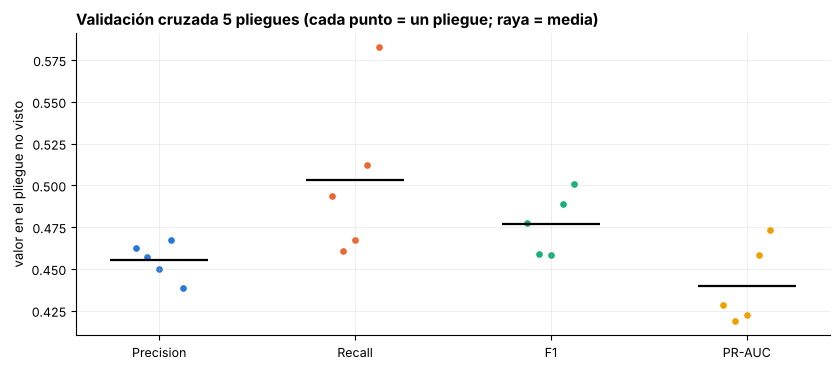

In [ ]:
print("Validación cruzada estratificada (5 pliegues) de la configuración final")
X_all = X.iloc[np.r_[idx_tr, idx_va]].reset_index(drop=True); y_all = y[np.r_[idx_tr, idx_va]]
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
filas_cv = []
for f, (a, b) in enumerate(skf.split(X_all, y_all)):
    Xa, Xb, ya, yb = X_all.iloc[a], X_all.iloc[b], y_all[a], y_all[b]
    ia, iv = train_test_split(np.arange(len(a)), test_size=0.15, stratify=ya, random_state=SEED)
    ct_f = crear_transformador(); fe = lambda d: ingenieria(d)
    dat_f = dict(Xtr=ct_f.fit_transform(fe(Xa.iloc[ia])).astype("float32"), Xva=ct_f.transform(fe(Xa.iloc[iv])).astype("float32"),
                 ytr=ya[ia], yva=ya[iv])
    mod, h, pv, dur, be = entrenar(dat_f, CFG_FINAL, SEED + f, **KW_FINAL)
    thr, _ = umbral_optimo(dat_f["yva"], pv)
    pt = proba(mod, ct_f.transform(fe(Xb)).astype("float32"))
    met = metricas(yb, pt, thr); met["umbral"] = thr
    filas_cv.append(met); keras.backend.clear_session()
    print(f"  pliegue {f+1}: F1={met['f1']:.3f}  Precision={met['precision']:.3f}  Recall={met['recall']:.3f}  PR-AUC={met['pr_auc']:.3f}")
cv = pd.DataFrame(filas_cv)
resumen_cv = pd.DataFrame({"media": cv.mean(), "desv. estándar": cv.std(ddof=0)}).T.round(3)
display(resumen_cv)
RESULTADOS["cv"] = json.loads(resumen_cv.to_json(orient="index"))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for k, (col, lab) in enumerate([("precision", "Precision"), ("recall", "Recall"), ("f1", "F1"), ("pr_auc", "PR-AUC")]):
    ax.scatter(np.full(5, k) + np.linspace(-0.12, 0.12, 5), cv[col], s=34, color=COLORES[k], edgecolor="white")
    ax.hlines(cv[col].mean(), k - 0.25, k + 0.25, color="black", lw=1.6)
ax.set_xticks(range(4)); ax.set_xticklabels(["Precision", "Recall", "F1", "PR-AUC"]); ax.set_ylabel("valor en el pliegue no visto")
ax.set_title("Validación cruzada 5 pliegues (cada punto = un pliegue; raya = media)")
plt.tight_layout(); guardar("cv"); plt.show()

### Análisis: validación cruzada (5 pliegues)

| Métrica | Media | Desv. estándar | Rango observado |
|---|---|---|---|
| Accuracy | 0,871 | 0,004 | — |
| Precision | 0,455 | 0,010 | 0,439–0,468 |
| Recall | 0,503 | 0,044 | 0,461–0,583 |
| F1 | **0,477** | 0,017 | 0,458–0,501 |
| PR-AUC | **0,440** | 0,022 | 0,419–0,473 |
| ROC-AUC | 0,789 | 0,012 | — |

* **El rendimiento es consistente pero no idéntico entre particiones**: F1 entre 0,458 y 0,501 y PR-AUC entre 0,419 y 0,473. El resultado en prueba (F1 0,461, PR-AUC 0,424) está dentro de ese rango, en la parte baja: la partición de prueba resultó algo más difícil que el promedio. Una sola partición habría dado una impresión más precisa de la que realmente tenemos; **la cifra honesta es "F1 ≈ 0,46–0,48 ± 0,02"**.
* **El Recall es la métrica más variable** (± 0,044) porque depende del umbral, que en cada pliegue se elige con un conjunto de validación pequeño (~15 % del pliegue de entrenamiento). Mejorar la elección del umbral (más datos de validación, calibración) reduciría esa variabilidad.

## 10. Conclusiones

### 10.1 Resultado
Se construyó un **MLP en TensorFlow/Keras** para predecir si un cliente contratará un depósito a plazo **antes de llamarlo** (sin la variable `duration`). El modelo final —**128-64 neuronas, ReLU, BatchNorm, Dropout 0,2, L2 1e-4, Adam (lr 1e-3), batch 512, pesos de clase, Early Stopping, umbral 0,71 elegido en validación**— obtiene en el conjunto de prueba **F1 = 0,461, Precision = 0,465, Recall = 0,458, PR-AUC = 0,424 y ROC-AUC = 0,795** (validación cruzada: F1 0,477 ± 0,017). Es **4 veces más eficiente que llamar al azar** y captura el **60 %** de las contrataciones llamando al 20 % de los clientes con mayor puntaje.

### 10.2 Decisiones y la evidencia que las respalda
| Decisión | Valor final | Evidencia |
|---|---|---|
| Excluir `duration` | Sí | Fuga de información: PR-AUC 0,591 vs 0,433 (sección 3.3) |
| Transformar y escalar numéricas | log + estandarización | Sin ello PR-AUC 0,303 e inestable (3.3) |
| Épocas | Early Stopping (óptimo ≈ 15) | Sobreajuste desde la época ~15 (4.3) |
| Tasa de aprendizaje | 1e-3 | 1e-2 y 1e-1 inestables y peores (4.4) |
| Batch | 512 | Rapidez y estabilidad; mejor en la búsqueda (4.5, 7.1) |
| Arquitectura | 128-64 | Redes grandes sobreajustan sin regularización; 2 capas basta (4.6, 7.1) |
| Activación oculta | ReLU | Mayor PR-AUC y más rápida con la config. final (7.2); sin desvanecimiento (5.2) |
| Salida y pérdida | Sigmoide + BCE con pesos de clase | Igual PR-AUC que BCE, atiende a la clase minoritaria (5.3) |
| Optimizador | Adam | Robusto y rápido; no demostrado superior (6.1) |
| Regularización | BatchNorm + Dropout + L2 + Early Stopping | +0,16 de PR-AUC y estabilidad (6.2) |
| Inicialización | Glorot (He en redes profundas) | Ceros no aprende (PR-AUC = azar) (6.3) |
| Umbral | 0,71 (validación) | F1 0,357 → 0,461 solo por elegir el umbral (8.1) |

### 10.3 Lo más importante que aprendimos
1. **El sobreajuste fue el problema dominante.** Casi todos los "efectos" de parámetros a épocas fijas (lr, batch, arquitectura, optimizador) eran, en el fondo, efectos sobre *qué tan rápido sobreajusta* la red. Regularizar y parar a tiempo valió mucho más (+0,16 de PR-AUC) que afinar hiperparámetros (+0,011).
2. **Elegir bien la métrica y el umbral importa más que la arquitectura.** Con 88 % de negativos la Accuracy engaña; el mayor salto de F1 vino del umbral.
3. **El problema es "casi lineal"** y de señal moderada: la red supera a la regresión logística (F1 +0,03; PR-AUC +0,04) pero sin saltos espectaculares.
4. **Replicar y no sobreinterpretar:** con una sola semilla habríamos elegido otra configuración; las diferencias de ~0,005 de PR-AUC están dentro del ruido.

### 10.4 Limitaciones
* La partición es aleatoria, no temporal: las variables `month`, `day` y `contact` pueden capturar patrones de la campaña que no se repetirán.
* Los experimentos controlados de las secciones 4 a 6 comparan a **épocas fijas**; la comparación de optimizadores, lr y batch con Early Stopping podría cambiar los rankings.
* Las probabilidades del modelo final no están calibradas (por los pesos de clase) y el umbral se eligió maximizando F1, no un costo de negocio real.
* No se probó el recorte de gradientes (*gradient clipping*), que el material 1.6.1 propone contra la explosión del gradiente; con redes de 2–3 capas y entradas estandarizadas no aparecieron sus síntomas (pérdidas NaN o saltos bruscos de la función de costo).
* Una búsqueda de 20 configuraciones es pequeña; el paisaje plano sugiere que más búsqueda rendiría poco, pero no lo demostramos.

### 10.5 Mejoras propuestas
Comparar con árboles potenciados (XGBoost/LightGBM); calibrar probabilidades y elegir el umbral por costo/beneficio; ingeniería de variables y *embeddings*; ensamble de semillas; validación con partición temporal; y repetir la comparación de optimizadores con Early Stopping.

In [ ]:
# Exporta todas las tablas para reutilizarlas en la presentación
with open("resultados.json", "w", encoding="utf-8") as f:
    json.dump(RESULTADOS, f, ensure_ascii=False, indent=1, default=float)
print("Guardado resultados.json y", len(os.listdir("figuras")), "figuras en ./figuras")
print(f"Tiempo total de ejecución: {(time.time() - T0) / 60:.1f} minutos")

Guardado resultados.json y 28 figuras en ./figuras
Tiempo total de ejecución: 60.2 minutos


## 11. Referencias
* Moro, S., Cortez, P. & Rita, P. (2014). *A data-driven approach to predict the success of bank telemarketing.* Decision Support Systems, 62, 22–31. Dataset: UCI Machine Learning Repository — Bank Marketing (CC BY 4.0). https://archive.ics.uci.edu/dataset/222/bank+marketing
* Material de la asignatura DLY0100 (Duoc UC, Escuela de Informática, 2025): 1.1.1 Introducción al Deep Learning · 1.1.3 Aplicaciones de Deep Learning · 1.2.1 El Perceptrón · 1.2.3 Redes Fully Connected Feed Forward · 1.3.1 Descenso del Gradiente · 1.4.1 Backpropagation · 1.4.2 Generalización y Métricas · 1.5.1 Técnicas de Regularización · 1.6.1 Desvanecimiento y Explosión del Gradiente · 1.6.2 Optimizadores.
* Chollet, F. *Deep Learning with Python.* Manning.
* Bergstra, J. & Bengio, Y. (2012). *Random Search for Hyper-Parameter Optimization.* JMLR 13.
* Glorot, X. & Bengio, Y. (2010) · He, K. et al. (2015) · Ioffe, S. & Szegedy, C. (2015) · Srivastava, N. et al. (2014) · Kingma, D. & Ba, J. (2015) · Lin, T.-Y. et al. (2017, *Focal Loss*).
* Documentación oficial: TensorFlow/Keras https://www.tensorflow.org/api_docs · scikit-learn https://scikit-learn.org/stable/modules/model_evaluation.html